# Statistical Characterization of Thesis Datasets

Notebook for exploratory/statistical analysis of the datasets used in the GA-based automatic decision-tree inducer.

In [1]:
# =========================
# 0. Imports and setup
# =========================

from pathlib import Path
import sys
import random
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, skew, kurtosis, zscore, kruskal, f_oneway
from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.feature_selection import mutual_info_classif, chi2

random.seed(42)
np.random.seed(42)


In [2]:
# =========================
# 1. Project root and datasets
# =========================

from pathlib import Path
import sys

def find_project_root(start: Path, marker="core"):
    for parent in [start] + list(start.parents):
        if (parent / marker).exists():
            return parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

random.seed(42)
data_path = PROJECT_ROOT / "data"

datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

# Edit this list to only include the datasets to analyse
selected_dataset_names = list(datasets.keys())
datasets = {name: path for name, path in datasets.items() if name in selected_dataset_names}

print("Project root:", PROJECT_ROOT)
print("Data path:", data_path)
print("Datasets selected:", list(datasets.keys()))


Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Data path: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\data
Datasets selected: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red', 'iris', 'haberman', 'parkinsons', 'banknote', 'credit_approval']


## 2. Target-column handling

The previous version assumed that the **last column** was the target. That is unsafe for several UCI-style files.

Important corrections:

- `balance_scale`: target is the balance class, usually the **first** column (`class`), not the last numeric attribute.
- `parkinsons`: target is `status`; `name` is an identifier and should be removed from the predictors.
- CV is now fixed to the same repeated 5-fold protocol for all eligible datasets. Datasets with fewer than five samples in at least one class are marked as non-comparable instead of being silently evaluated with two folds.


In [3]:
# =========================
# 2. Target configuration and loader
# =========================

# Explicit target/ID handling. Values may be column names, integer positions, or
# an ordered list of fallbacks. This prevents accidental target leakage or
# target-column mistakes when the label is not the final column.
TARGET_OVERRIDES = {
    "balance_scale": ["class", "Class", "balance", "Balance", 0],
    "parkinsons": ["status", "Status"],
    # Add more explicit targets here when needed, e.g.
    # "heart_disease": "target",
    # "iris": "class",
    # "wine_red": "quality",
}

ID_COLUMNS = {
    # Patient/sample identifiers should not be predictive features.
    "parkinsons": ["name", "Name"],
}

MISSING_TOKENS = ["?", "NA", "N/A", "na", "n/a", "", " ", "null", "None"]


def _resolve_column(df, spec, dataset_name, purpose):
    """Resolve a column spec that can be a name, integer position, or fallback list."""
    specs = spec if isinstance(spec, (list, tuple)) else [spec]

    for candidate in specs:
        if isinstance(candidate, int):
            if -len(df.columns) <= candidate < len(df.columns):
                return df.columns[candidate]
        elif candidate in df.columns:
            return candidate

    available = list(df.columns)
    raise ValueError(
        f"Could not resolve {purpose} for {dataset_name}. "
        f"Tried {specs}; available columns: {available}"
    )


def _resolve_existing_columns(df, specs):
    """Return only the configured columns that exist in this concrete CSV."""
    resolved = []
    for spec in specs:
        try:
            col = _resolve_column(df, spec, "dataset", "ID column")
            if col not in resolved:
                resolved.append(col)
        except ValueError:
            pass
    return resolved


def load_dataset(name, path):
    # Load a CSV and split into X and y.
    df = pd.read_csv(path, na_values=MISSING_TOKENS)
    df.columns = [str(c).strip() for c in df.columns]

    target_spec = TARGET_OVERRIDES.get(name, -1)
    target_col = _resolve_column(df, target_spec, name, "target column")

    id_cols = _resolve_existing_columns(df, ID_COLUMNS.get(name, []))
    id_cols = [c for c in id_cols if c != target_col]

    X = df.drop(columns=[target_col] + id_cols).copy()
    y = df[target_col].copy()

    valid_target = ~y.isna()
    X = X.loc[valid_target].reset_index(drop=True)
    y = y.loc[valid_target].reset_index(drop=True)

    y_encoded = LabelEncoder().fit_transform(y.astype(str))

    return {
        "df": df,
        "X": X,
        "y": y_encoded,
        "y_raw": y,
        "target_col": target_col,
        "dropped_id_cols": id_cols,
    }


loaded = {}
target_audit_rows = []

for name, path in datasets.items():
    try:
        obj = load_dataset(name, path)
        loaded[name] = obj
        y_raw = obj["y_raw"]

        target_audit_rows.append({
            "dataset": name,
            "target_col": obj["target_col"],
            "dropped_id_cols": ", ".join(obj["dropped_id_cols"]),
            "n_rows": obj["X"].shape[0],
            "n_features": obj["X"].shape[1],
            "n_classes": pd.Series(obj["y"]).nunique(),
            "min_class_count": pd.Series(obj["y"]).value_counts().min(),
            "class_counts_raw": dict(y_raw.value_counts().sort_index()),
        })

        print(
            f"Loaded {name}: {obj['X'].shape[0]} rows, {obj['X'].shape[1]} features, "
            f"target='{obj['target_col']}', dropped_id_cols={obj['dropped_id_cols']}"
        )
    except Exception as e:
        print(f"[ERROR] Could not load {name}: {e}")

target_audit_df = pd.DataFrame(target_audit_rows).sort_values("dataset")
target_audit_df


Loaded abalone: 4177 rows, 8 features, target='target', dropped_id_cols=[]
Loaded anneal: 798 rows, 38 features, target='target', dropped_id_cols=[]
Loaded arrhythmia: 452 rows, 279 features, target='target', dropped_id_cols=[]
Loaded bridges: 108 rows, 11 features, target='target', dropped_id_cols=[]
Loaded balance_scale: 625 rows, 4 features, target='class', dropped_id_cols=[]
Loaded car: 1728 rows, 6 features, target='target', dropped_id_cols=[]
Loaded cylinder_bands: 540 rows, 39 features, target='target', dropped_id_cols=[]
Loaded glass: 214 rows, 9 features, target='target', dropped_id_cols=[]
Loaded heart_disease: 303 rows, 13 features, target='13', dropped_id_cols=[]
Loaded ionosphere: 351 rows, 34 features, target='34', dropped_id_cols=[]
Loaded semeion: 1593 rows, 256 features, target='target', dropped_id_cols=[]
Loaded sonar: 208 rows, 60 features, target='60', dropped_id_cols=[]
Loaded tic_tac_toe: 958 rows, 9 features, target='9', dropped_id_cols=[]
Loaded breast_cancer: 5

,dataset,target_col,dropped_id_cols,n_rows,n_features,n_classes,min_class_count,class_counts_raw
0,abalone,target,,4177,8,28,1,"{0: 1, 1: 634, 2: 487, 3: 267, 4: 203, 5: 126,..."
1,anneal,target,,798,38,5,8,"{0: 8, 1: 88, 2: 608, 3: 60, 4: 34}"
2,arrhythmia,target,,452,279,13,2,"{0.0: 245, 1.0: 50, 2.0: 4, 3.0: 5, 4.0: 22, 5..."
4,balance_scale,class,,625,4,3,49,"{'B': 49, 'L': 288, 'R': 288}"
18,banknote,4,,1372,4,2,610,"{0: 762, 1: 610}"
13,breast_cancer,target,,569,30,2,212,"{0.0: 212, 1.0: 357}"
3,bridges,target,,108,11,8,1,"{0: 13, 1: 11, 2: 10, 3: 1, 4: 44, 5: 11, 6: 1..."
5,car,target,,1728,6,4,65,"{0: 384, 1: 69, 2: 1210, 3: 65}"
19,credit_approval,15,,690,15,2,307,"{'+': 307, '-': 383}"
6,cylinder_bands,target,,540,39,2,228,"{0: 228, 2: 312}"


### Target audit

Run this immediately after loading. It makes target mistakes visible before any statistical summaries or baselines are calculated.

In [4]:
# Explicit checks for the two datasets that motivated this revision.
expected_targets = {
    "balance_scale": {"class", "Class", "balance", "Balance"},
    "parkinsons": {"status", "Status"},
}

for dataset_name, expected in expected_targets.items():
    if dataset_name in loaded:
        actual = loaded[dataset_name]["target_col"]
        if actual not in expected:
            raise AssertionError(
                f"{dataset_name}: expected target in {expected}, got {actual!r}. "
                "Check the CSV header and TARGET_OVERRIDES."
            )

target_audit_df

,dataset,target_col,dropped_id_cols,n_rows,n_features,n_classes,min_class_count,class_counts_raw
0,abalone,target,,4177,8,28,1,"{0: 1, 1: 634, 2: 487, 3: 267, 4: 203, 5: 126,..."
1,anneal,target,,798,38,5,8,"{0: 8, 1: 88, 2: 608, 3: 60, 4: 34}"
2,arrhythmia,target,,452,279,13,2,"{0.0: 245, 1.0: 50, 2.0: 4, 3.0: 5, 4.0: 22, 5..."
4,balance_scale,class,,625,4,3,49,"{'B': 49, 'L': 288, 'R': 288}"
18,banknote,4,,1372,4,2,610,"{0: 762, 1: 610}"
13,breast_cancer,target,,569,30,2,212,"{0.0: 212, 1.0: 357}"
3,bridges,target,,108,11,8,1,"{0: 13, 1: 11, 2: 10, 3: 1, 4: 44, 5: 11, 6: 1..."
5,car,target,,1728,6,4,65,"{0: 384, 1: 69, 2: 1210, 3: 65}"
19,credit_approval,15,,690,15,2,307,"{'+': 307, '-': 383}"
6,cylinder_bands,target,,540,39,2,228,"{0: 228, 2: 312}"


## 3. Dataset-level summary

This gives sample size, dimensionality, class count, missingness, imbalance ratio, and class entropy.

In [5]:
# =========================
# 3. Dataset-level summary
# =========================

def class_entropy(y):
    counts = np.bincount(y)
    probs = counts / counts.sum()
    return entropy(probs, base=2)


def imbalance_ratio(y):
    counts = np.bincount(y)
    return counts.max() / counts.min() if counts.min() > 0 else np.inf

summary_rows = []
class_distribution_rows = []

for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    n_rows, n_features = X.shape
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    counts = pd.Series(y).value_counts(normalize=False).sort_index()
    props = pd.Series(y).value_counts(normalize=True).sort_index()

    summary_rows.append({
        "dataset": name,
        "n_samples": n_rows,
        "n_features": n_features,
        "n_numeric": len(numeric_cols),
        "n_categorical": len(categorical_cols),
        "n_classes": len(np.unique(y)),
        "missing_pct": X.isna().mean().mean() * 100,
        "class_entropy": class_entropy(y),
        "imbalance_ratio": imbalance_ratio(y),
        "samples_per_feature": n_rows / max(n_features, 1),
    })

    for cls in counts.index:
        class_distribution_rows.append({
            "dataset": name,
            "class": cls,
            "count": counts.loc[cls],
            "proportion": props.loc[cls],
        })

summary_df = pd.DataFrame(summary_rows).sort_values("dataset")
class_distribution_df = pd.DataFrame(class_distribution_rows)

output_dir = PROJECT_ROOT / "results" / "dataset_statistics"
output_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(output_dir / "dataset_summary.csv", index=False)
class_distribution_df.to_csv(output_dir / "class_distribution.csv", index=False)

summary_df


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature
0,abalone,4177,8,7,1,28,0.000000,3.602007,689.000000,522.125000
1,anneal,798,38,16,22,5,64.938662,1.190925,76.000000,21.000000
2,arrhythmia,452,279,279,0,13,0.323532,2.401386,122.500000,1.620072
4,balance_scale,625,4,4,0,3,0.000000,1.318116,5.877551,156.250000
18,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000
13,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667
3,bridges,108,11,4,7,8,6.313131,2.461855,44.000000,9.818182
5,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000
19,credit_approval,690,15,6,9,2,0.647343,0.991231,1.247557,46.000000
6,cylinder_bands,540,39,24,15,2,4.743590,0.982474,1.368421,13.846154


## 4. Class balance plots

Important for macro-F1 and for understanding whether a tree may bias itself toward majority classes.

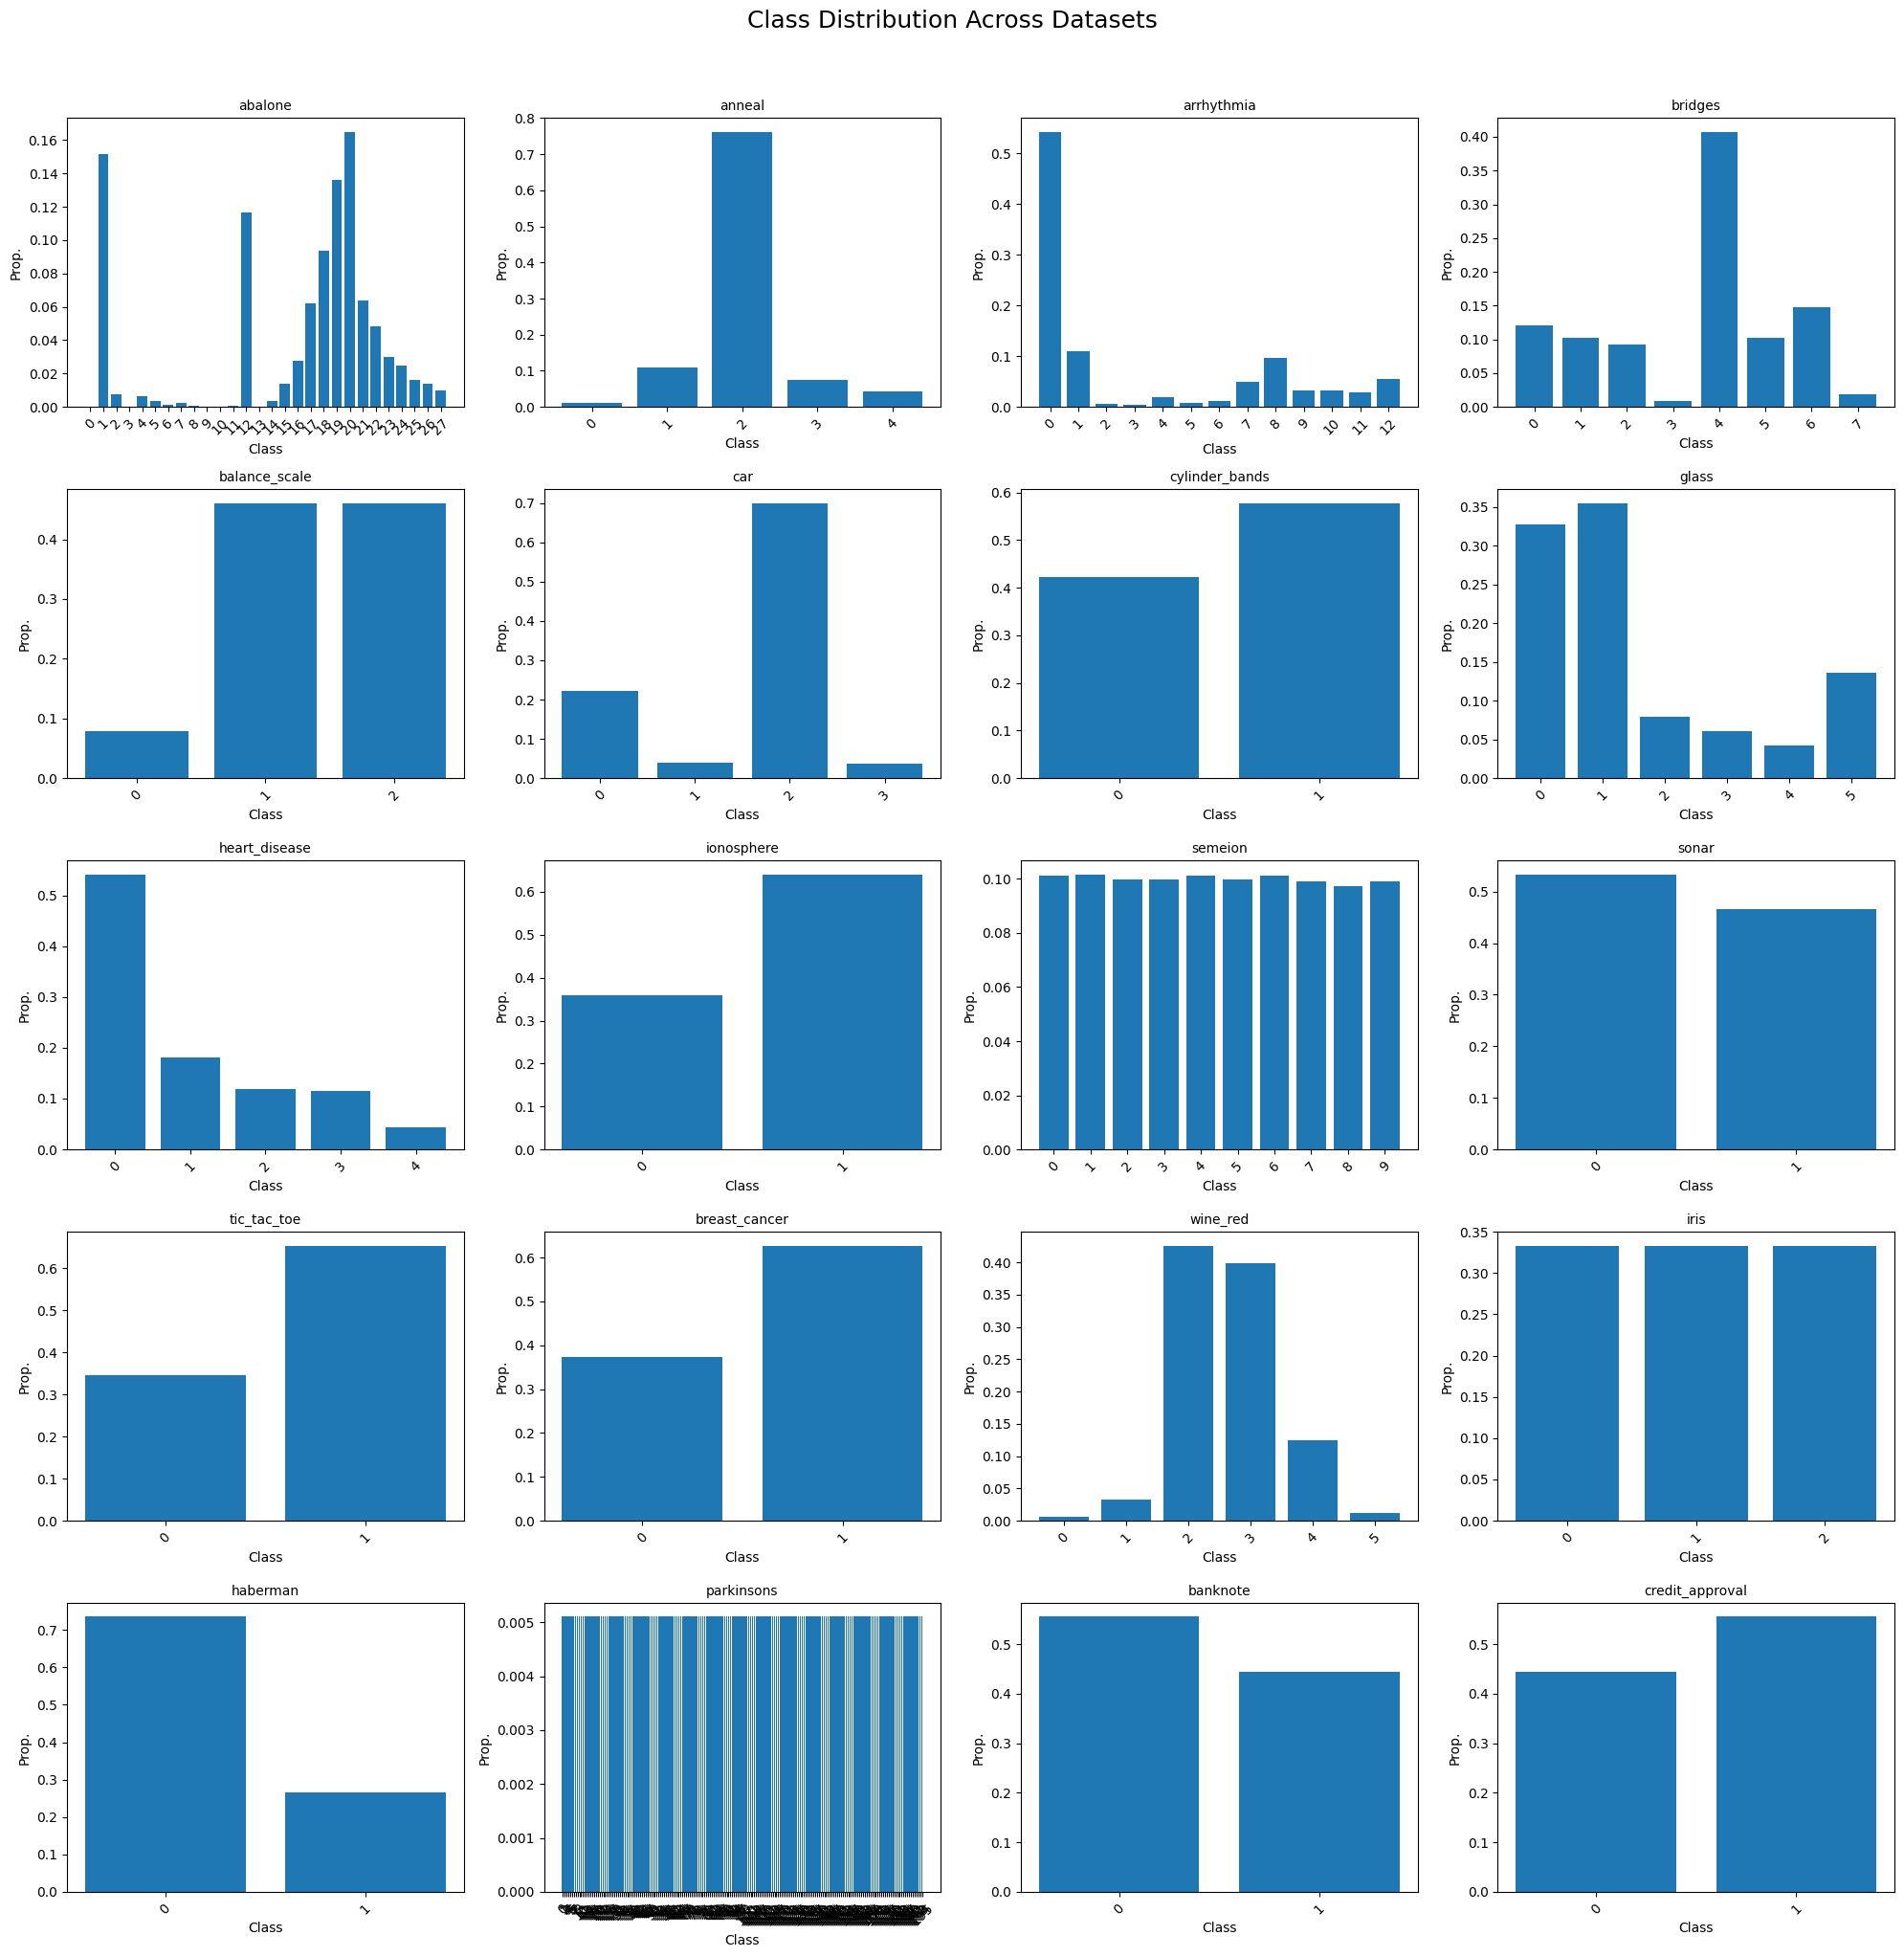

In [6]:
# ==========================================
# 4. CLASS BALANCE PLOTS (ALL TOGETHER)
# ==========================================

datasets_names = list(loaded.keys())

n_datasets = len(datasets_names)

# Grid size
cols = 4
rows = math.ceil(n_datasets / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))

# Flatten axes for easier iteration
axes = axes.flatten()

for idx, name in enumerate(datasets_names):

    temp = class_distribution_df[
        class_distribution_df["dataset"] == name
    ]

    axes[idx].bar(
        temp["class"].astype(str),
        temp["proportion"]
    )

    axes[idx].set_title(name, fontsize=10)
    axes[idx].set_xlabel("Class")
    axes[idx].set_ylabel("Prop.")

    axes[idx].tick_params(axis='x', rotation=45)

# Remove unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Class Distribution Across Datasets",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()


## 5. Missing values analysis

This tells whether missing-value handling genes are likely to matter.

In [7]:
missing_rows = []
for name, obj in loaded.items():
    X = obj["X"]
    missing_by_feature = X.isna().mean().sort_values(ascending=False) * 100
    for feature, pct in missing_by_feature.items():
        if pct > 0:
            missing_rows.append({"dataset": name, "feature": feature, "missing_pct": pct})

missing_df = pd.DataFrame(missing_rows)
missing_df.to_csv(output_dir / "missing_values_by_feature.csv", index=False)
missing_df.head(30)


,dataset,feature,missing_pct
0,anneal,feature_022,100.000000
1,anneal,feature_029,100.000000
2,anneal,feature_030,100.000000
3,anneal,feature_025,100.000000
4,anneal,feature_028,100.000000
5,anneal,feature_018,100.000000
6,anneal,feature_013,99.874687
7,anneal,feature_023,99.749373
8,anneal,feature_026,99.373434
9,anneal,feature_020,99.122807


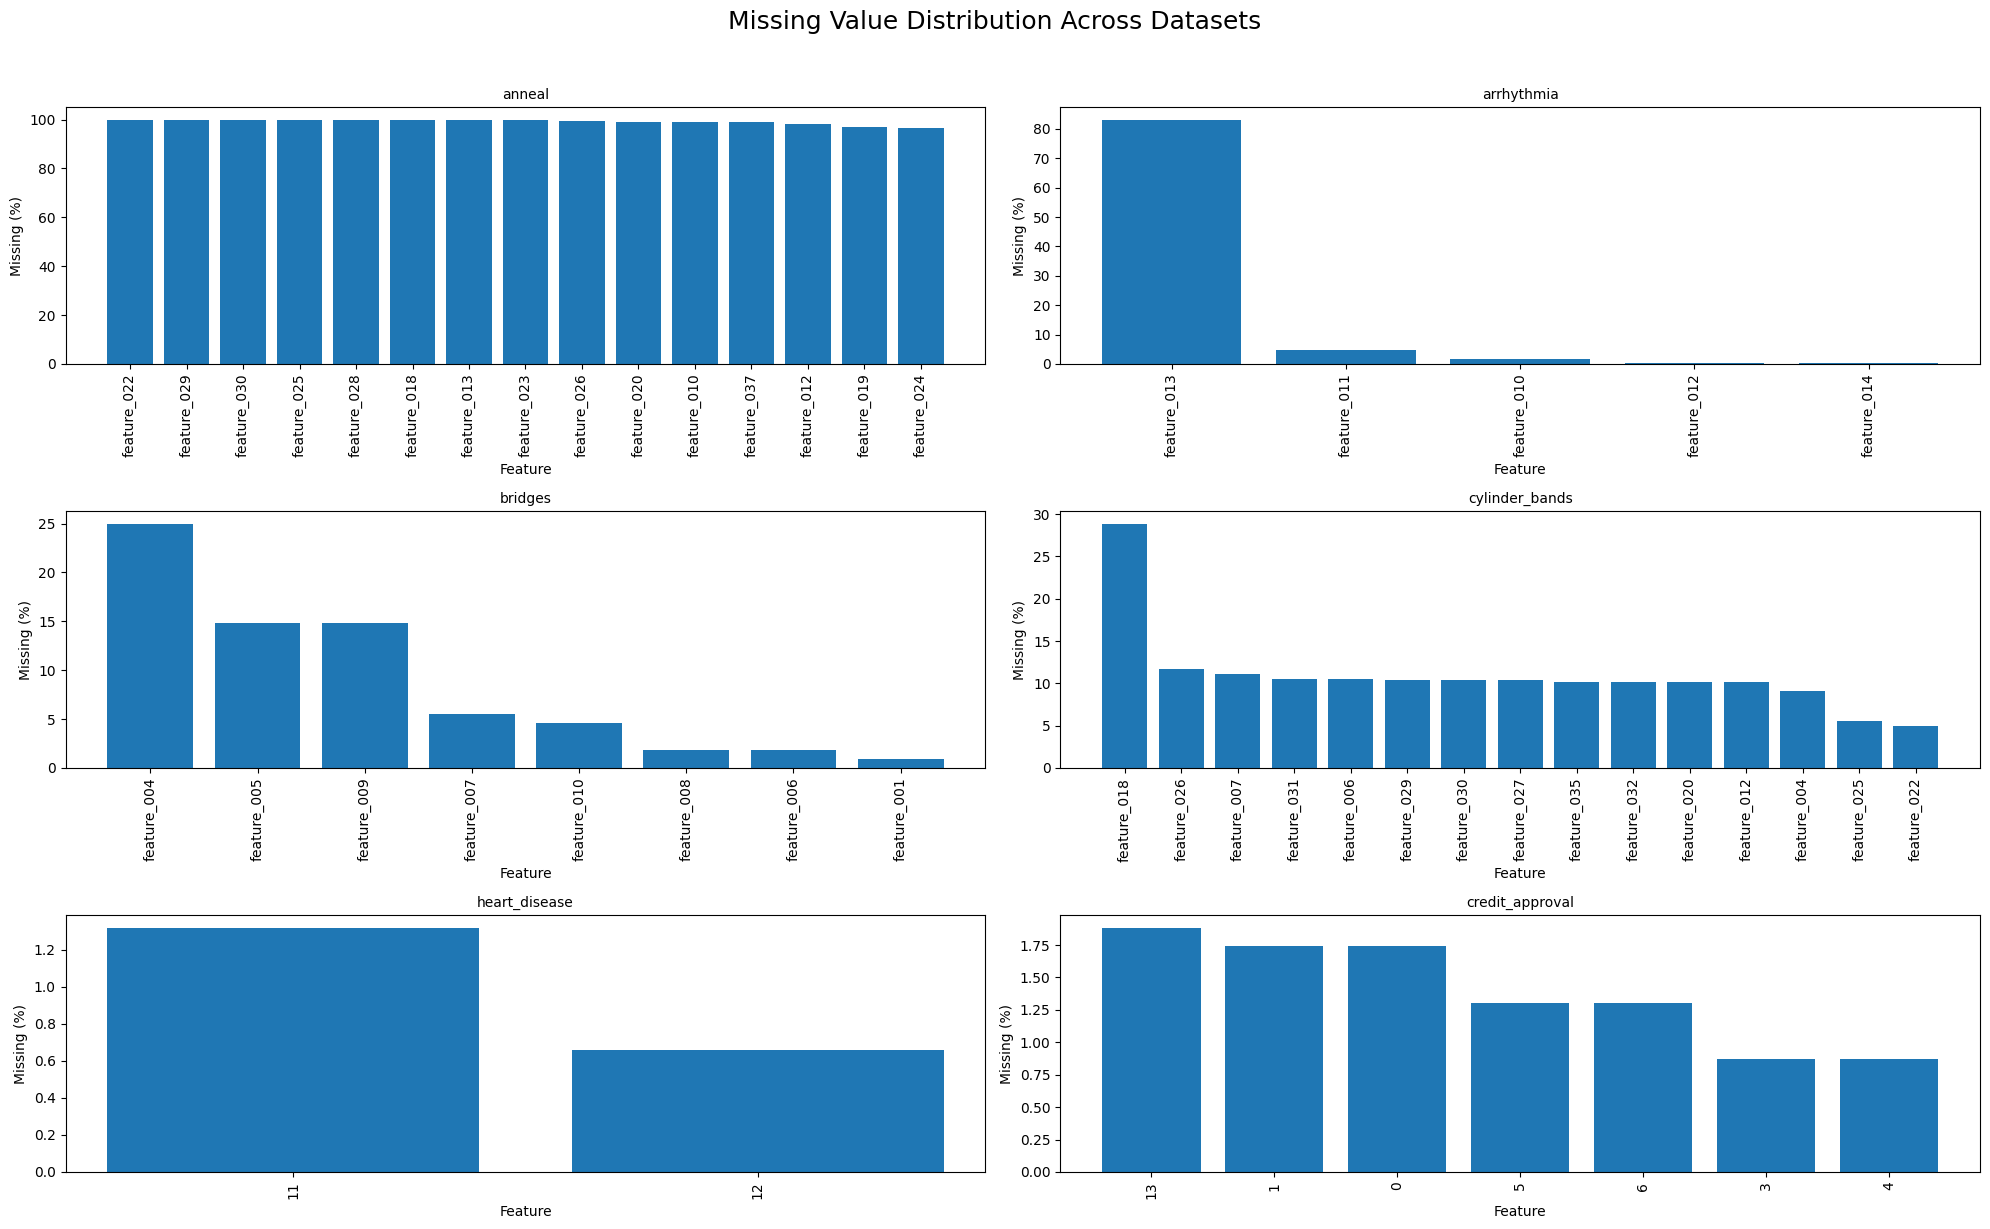

In [8]:
# ==========================================
# MISSING VALUE ANALYSIS (ALL TOGETHER)
# ==========================================
import math
if not missing_df.empty:

    datasets_with_missing = missing_df["dataset"].unique()

    n_datasets = len(datasets_with_missing)

    cols = 2
    rows = math.ceil(n_datasets / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(20, rows * 4)
    )

    axes = axes.flatten()

    for idx, name in enumerate(datasets_with_missing):

        temp = missing_df[
            missing_df["dataset"] == name
        ].head(15)

        axes[idx].bar(
            temp["feature"].astype(str),
            temp["missing_pct"]
        )

        axes[idx].set_title(name, fontsize=10)
        axes[idx].set_xlabel("Feature")
        axes[idx].set_ylabel("Missing (%)")

        axes[idx].tick_params(
            axis='x',
            rotation=90
        )

    # Remove empty subplots
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(
        "Missing Value Distribution Across Datasets",
        fontsize=18,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## 6. Numeric descriptive statistics

Mean, median, standard deviation, skewness, kurtosis, and unique values.

In [9]:
descriptive_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        descriptive_rows.append({
            "dataset": name,
            "feature": feature,
            "mean": s.mean(),
            "median": s.median(),
            "std": s.std(),
            "min": s.min(),
            "max": s.max(),
            "skewness": skew(s),
            "kurtosis": kurtosis(s),
            "n_unique": s.nunique(),
        })

descriptive_df = pd.DataFrame(descriptive_rows)
descriptive_df.to_csv(output_dir / "numeric_descriptive_statistics.csv", index=False)
descriptive_df.head(20)


,dataset,feature,mean,median,std,min,max,skewness,kurtosis,n_unique
0,abalone,feature_001,0.523992,0.5450,0.120093,0.0750,0.8150,-0.639643,0.063108,134
1,abalone,feature_002,0.407881,0.4250,0.099240,0.0550,0.6500,-0.608979,-0.046857,111
2,abalone,feature_003,0.139516,0.1400,0.041827,0.0000,1.1300,3.127694,75.933099,51
3,abalone,feature_004,0.828742,0.7995,0.490389,0.0020,2.8255,0.530768,-0.025051,2429
4,abalone,feature_005,0.359367,0.3360,0.221963,0.0010,1.4880,0.718840,0.592975,1515
5,abalone,feature_006,0.180594,0.1710,0.109614,0.0005,0.7600,0.591640,0.082475,880
6,abalone,feature_007,0.238831,0.2340,0.139203,0.0015,1.0050,0.620704,0.529854,926
7,anneal,feature_003,3.547619,0.0000,13.592644,0.0000,70.0000,3.815705,13.020051,10
8,anneal,feature_004,11.748120,0.0000,24.621001,0.0000,85.0000,1.821492,1.835243,7
9,anneal,feature_007,2.223301,2.0000,0.659148,1.0000,5.0000,1.194513,3.939406,4


## 7. Low-variance features

Low-variance features may provide little information for splits.

In [10]:
low_variance_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        low_variance_rows.append({
            "dataset": name,
            "feature": feature,
            "variance": s.var(),
            "n_unique": s.nunique(),
        })

low_variance_df = pd.DataFrame(low_variance_rows).sort_values(["dataset", "variance"])
low_variance_df.to_csv(output_dir / "low_variance_features.csv", index=False)
low_variance_df.head(30)


,dataset,feature,variance,n_unique
2,abalone,feature_003,1.749503e-03,51
1,abalone,feature_002,9.848551e-03,111
5,abalone,feature_006,1.201528e-02,880
0,abalone,feature_001,1.442231e-02,134
6,abalone,feature_007,1.937738e-02,926
4,abalone,feature_005,4.926755e-02,1515
3,abalone,feature_004,2.404814e-01,2429
16,anneal,feature_037,1.111111e-01,2
11,anneal,feature_012,2.564103e-01,2
9,anneal,feature_007,4.344755e-01,4


## 8. Outlier analysis

Outliers are estimated using IQR and z-score. They can affect threshold-based splits.

In [11]:
outlier_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) < 3:
            continue
        q1, q3 = np.percentile(s, [25, 75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        iqr_outliers = ((s < lower) | (s > upper)).mean() * 100
        z_outliers = (np.abs(zscore(s)) > 3).mean() * 100
        outlier_rows.append({
            "dataset": name,
            "feature": feature,
            "iqr_outlier_pct": iqr_outliers,
            "zscore_outlier_pct": z_outliers,
        })

outlier_df = pd.DataFrame(outlier_rows)
outlier_df.to_csv(output_dir / "outlier_analysis.csv", index=False)
outlier_df.sort_values(["dataset", "iqr_outlier_pct"], ascending=[True, False]).head(30)


,dataset,feature,iqr_outlier_pct,zscore_outlier_pct
1,abalone,feature_002,1.412497,0.311228
0,abalone,feature_001,1.173091,0.359109
4,abalone,feature_005,1.149150,0.885803
6,abalone,feature_007,0.837922,0.646397
3,abalone,feature_004,0.718219,0.454872
2,abalone,feature_003,0.694278,0.119703
5,abalone,feature_006,0.622456,0.526694
14,anneal,feature_034,22.431078,0.000000
8,anneal,feature_004,19.799499,0.000000
16,anneal,feature_037,11.111111,0.000000


## 9. Feature-class separability tests

For numeric features:

- ANOVA checks whether mean values differ across classes.
- Kruskal-Wallis is a non-parametric alternative.

Small p-values suggest that the feature may help separate classes.

In [12]:
separability_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    numeric_X = X.select_dtypes(include=[np.number])
    classes = np.unique(y)
    for feature in numeric_X.columns:
        groups = []
        for cls in classes:
            values = numeric_X.loc[y == cls, feature].dropna().values
            if len(values) > 1:
                groups.append(values)
        if len(groups) < 2:
            continue
        try:
            anova_stat, anova_p = f_oneway(*groups)
        except Exception:
            anova_stat, anova_p = np.nan, np.nan
        try:
            kruskal_stat, kruskal_p = kruskal(*groups)
        except Exception:
            kruskal_stat, kruskal_p = np.nan, np.nan
        separability_rows.append({
            "dataset": name,
            "feature": feature,
            "anova_p": anova_p,
            "kruskal_p": kruskal_p,
            "anova_stat": anova_stat,
            "kruskal_stat": kruskal_stat,
        })

separability_df = pd.DataFrame(separability_rows)
separability_df.to_csv(output_dir / "feature_class_separability_tests.csv", index=False)
separability_df.sort_values(["dataset", "kruskal_p"]).head(30)


,dataset,feature,anova_p,kruskal_p,anova_stat,kruskal_stat
0,abalone,feature_001,0.000000e+00,0.000000e+00,228.612857,1883.888382
1,abalone,feature_002,0.000000e+00,0.000000e+00,238.311683,1941.808839
2,abalone,feature_003,0.000000e+00,0.000000e+00,150.803817,2009.722020
3,abalone,feature_004,0.000000e+00,0.000000e+00,138.677333,1945.096267
4,abalone,feature_005,0.000000e+00,0.000000e+00,98.630296,1650.491201
5,abalone,feature_006,0.000000e+00,0.000000e+00,126.753934,1894.927766
6,abalone,feature_007,0.000000e+00,0.000000e+00,179.518538,2191.917129
8,anneal,feature_004,3.265697e-78,2.691340e-43,116.605005,205.324516
10,anneal,feature_008,2.641122e-26,1.498158e-22,34.127283,108.529543
12,anneal,feature_032,4.937191e-05,9.863091e-10,6.351938,47.908178


## 10. Correlation analysis

Highly correlated numeric features may indicate redundancy.

In [13]:
correlation_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    if numeric_X.shape[1] < 2:
        continue
    corr = numeric_X.corr(method="spearman").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_pairs = upper.stack().reset_index()
    high_pairs.columns = ["feature_1", "feature_2", "abs_spearman_corr"]
    high_pairs = high_pairs.sort_values("abs_spearman_corr", ascending=False)
    for _, row in high_pairs.head(20).iterrows():
        correlation_rows.append({
            "dataset": name,
            "feature_1": row["feature_1"],
            "feature_2": row["feature_2"],
            "abs_spearman_corr": row["abs_spearman_corr"],
        })

correlation_df = pd.DataFrame(correlation_rows)
correlation_df.to_csv(output_dir / "top_feature_correlations.csv", index=False)
correlation_df.head(30)


,dataset,feature_1,feature_2,abs_spearman_corr
0,abalone,feature_001,feature_002,0.983319
1,abalone,feature_004,feature_005,0.977060
2,abalone,feature_004,feature_006,0.975252
3,abalone,feature_001,feature_004,0.972633
4,abalone,feature_002,feature_004,0.971324
5,abalone,feature_004,feature_007,0.969426
6,abalone,feature_001,feature_005,0.956830
7,abalone,feature_002,feature_007,0.954149
8,abalone,feature_001,feature_006,0.952658
9,abalone,feature_002,feature_005,0.950472


## 11. Univariate feature importance

Mutual Information and Chi-square scores estimate individual predictive signal per feature.

In [14]:
def make_encoded_matrix(X):
    X_copy = X.copy()
    numeric_cols = X_copy.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X_copy.columns if c not in numeric_cols]
    parts = []
    feature_names = []

    if numeric_cols:
        X_num = Pipeline([("imputer", SimpleImputer(strategy="median"))]).fit_transform(X_copy[numeric_cols])
        parts.append(X_num)
        feature_names.extend(numeric_cols)

    if categorical_cols:
        X_cat = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ]).fit_transform(X_copy[categorical_cols].astype(str))
        parts.append(X_cat)
        feature_names.extend(categorical_cols)

    if not parts:
        return None, []
    return np.hstack(parts), feature_names

importance_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    X_encoded, feature_names = make_encoded_matrix(X)
    if X_encoded is None:
        continue
    try:
        mi = mutual_info_classif(X_encoded, y, random_state=42)
    except Exception:
        mi = np.full(X_encoded.shape[1], np.nan)
    try:
        X_nonnegative = MinMaxScaler().fit_transform(X_encoded)
        chi_scores, chi_p = chi2(X_nonnegative, y)
    except Exception:
        chi_scores = np.full(X_encoded.shape[1], np.nan)
        chi_p = np.full(X_encoded.shape[1], np.nan)
    for feature, mi_score, chi_score, p_val in zip(feature_names, mi, chi_scores, chi_p):
        importance_rows.append({
            "dataset": name,
            "feature": feature,
            "mutual_information": mi_score,
            "chi2_score": chi_score,
            "chi2_p": p_val,
        })

importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(output_dir / "univariate_feature_importance.csv", index=False)
importance_df.sort_values(["dataset", "mutual_information"], ascending=[True, False]).head(30)


,dataset,feature,mutual_information,chi2_score,chi2_p
6,abalone,feature_007,0.464273,166.254507,5.391010e-22
1,abalone,feature_002,0.406307,109.903884,5.762068e-12
3,abalone,feature_004,0.390034,182.963465,4.135206e-25
2,abalone,feature_003,0.375622,20.734631,7.985581e-01
5,abalone,feature_006,0.374857,147.825210,1.273761e-18
0,abalone,feature_001,0.371289,99.863833,2.709953e-10
4,abalone,feature_005,0.329069,133.046654,5.648614e-16
7,abalone,feature_000,0.162174,5.127324,9.999987e-01
13,anneal,feature_018,0.330094,5.256515,2.619753e-01
25,anneal,feature_001,0.287563,55.665645,2.356383e-11


## 12. Baseline performance and dataset difficulty dimensions

Baselines use macro-F1 under the same repeated stratified 5-fold protocol.

The dataset characterization is explicitly separated into three dimensions:

1. **Predictive difficulty**: low baseline macro-F1 plus high within-model CV instability.
2. **Strategy sensitivity**: disagreement between baseline algorithms.
3. **Computational burden**: runtime and tree-size/complexity indicators.

The primary Easy/Intermediate/Hard label is based only on predictive difficulty. Model spread, tree size, and runtime remain available as complementary experimental-profile descriptors, but they do not dominate the main difficulty category.


In [15]:
def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))

    # Use sparse_output when available; fall back for older scikit-learn.
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(transformers, remainder="drop")


# Comparable protocol: do not reduce to two folds for rare-class datasets.
# Every successful baseline below uses exactly 5 folds x 3 repeats = 15 scores.
CV_N_SPLITS = 5
CV_N_REPEATS = 3
CV_RANDOM_STATE = 42


def comparable_cv(y):
    counts = np.bincount(y)
    min_count = counts.min()
    if min_count < CV_N_SPLITS:
        return None, (
            f"min_class_count={min_count} < CV_N_SPLITS={CV_N_SPLITS}; "
            "not comparable under fixed 5-fold stratified CV"
        )

    # Repeated stratified CV improves the stability estimate while preserving
    # the same split protocol for every eligible dataset/model.
    from sklearn.model_selection import RepeatedStratifiedKFold
    return RepeatedStratifiedKFold(
        n_splits=CV_N_SPLITS,
        n_repeats=CV_N_REPEATS,
        random_state=CV_RANDOM_STATE,
    ), None


baseline_rows = []
cv_audit_rows = []
scorer = make_scorer(f1_score, average="macro", zero_division=0)

for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    cv, cv_issue = comparable_cv(y)

    cv_audit_rows.append({
        "dataset": name,
        "n_samples": len(y),
        "n_classes": len(np.unique(y)),
        "min_class_count": int(np.bincount(y).min()),
        "cv_n_splits": CV_N_SPLITS,
        "cv_n_repeats": CV_N_REPEATS,
        "n_scores_if_evaluated": CV_N_SPLITS * CV_N_REPEATS,
        "comparable_cv": cv is not None,
        "cv_issue": cv_issue or "",
    })

    if cv is None:
        print(f"[SKIP] {name}: {cv_issue}")
        baseline_rows.append({
            "dataset": name,
            "model": "ALL",
            "cv_folds": CV_N_SPLITS,
            "cv_repeats": CV_N_REPEATS,
            "n_scores": 0,
            "f1_macro_mean": np.nan,
            "f1_macro_std": np.nan,
            "f1_macro_min": np.nan,
            "f1_macro_max": np.nan,
            "scores": [],
            "runtime_seconds": np.nan,
            "mean_tree_nodes": np.nan,
            "mean_tree_depth": np.nan,
            "mean_tree_leaves": np.nan,
            "error": cv_issue,
        })
        continue

    models = {
        "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),
        "dummy_stratified": DummyClassifier(strategy="stratified", random_state=CV_RANDOM_STATE),
        "decision_tree_default": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=False)),
            ("model", DecisionTreeClassifier(random_state=CV_RANDOM_STATE)),
        ]),
        "decision_tree_balanced": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=False)),
            ("model", DecisionTreeClassifier(random_state=CV_RANDOM_STATE, class_weight="balanced")),
        ]),
        "logistic_regression": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=True)),
            ("model", LogisticRegression(
                max_iter=5000,
                random_state=CV_RANDOM_STATE,
                class_weight=None,
                solver="lbfgs",
            )),
        ]),
        "logistic_regression_balanced": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=True)),
            ("model", LogisticRegression(
                max_iter=5000,
                random_state=CV_RANDOM_STATE,
                class_weight="balanced",
                solver="lbfgs",
            )),
        ]),
    }

    for model_name, model in models.items():
        try:
            start_time = time.perf_counter()
            cv_result = cross_validate(
                model,
                X,
                y,
                cv=cv,
                scoring=scorer,
                n_jobs=-1,
                error_score="raise",
                return_estimator=model_name.startswith("decision_tree"),
            )
            runtime_seconds = time.perf_counter() - start_time
            scores = cv_result["test_score"]

            tree_nodes = tree_depths = tree_leaves = np.nan
            if model_name.startswith("decision_tree") and "estimator" in cv_result:
                fitted_trees = [est.named_steps["model"].tree_ for est in cv_result["estimator"]]
                tree_nodes = float(np.mean([tree.node_count for tree in fitted_trees]))
                tree_depths = float(np.mean([tree.max_depth for tree in fitted_trees]))
                tree_leaves = float(np.mean([tree.n_leaves for tree in fitted_trees]))

            baseline_rows.append({
                "dataset": name,
                "model": model_name,
                "cv_folds": CV_N_SPLITS,
                "cv_repeats": CV_N_REPEATS,
                "n_scores": len(scores),
                "f1_macro_mean": scores.mean(),
                "f1_macro_std": scores.std(ddof=1),
                "f1_macro_min": scores.min(),
                "f1_macro_max": scores.max(),
                "scores": list(scores),
                "runtime_seconds": runtime_seconds,
                "mean_tree_nodes": tree_nodes,
                "mean_tree_depth": tree_depths,
                "mean_tree_leaves": tree_leaves,
                "error": "",
            })
        except Exception as e:
            baseline_rows.append({
                "dataset": name,
                "model": model_name,
                "cv_folds": CV_N_SPLITS,
                "cv_repeats": CV_N_REPEATS,
                "n_scores": 0,
                "f1_macro_mean": np.nan,
                "f1_macro_std": np.nan,
                "f1_macro_min": np.nan,
                "f1_macro_max": np.nan,
                "scores": [],
                "runtime_seconds": np.nan,
                "mean_tree_nodes": np.nan,
                "mean_tree_depth": np.nan,
                "mean_tree_leaves": np.nan,
                "error": str(e),
            })

baseline_df = pd.DataFrame(baseline_rows)
cv_audit_df = pd.DataFrame(cv_audit_rows).sort_values("dataset")

# Dataset-level baseline characteristics.
#
# Important: CV variability is NOT calculated by pooling scores from all models.
# Pooling would mix two effects:
#   1. fold-to-fold instability within a model; and
#   2. genuine performance differences between algorithms.
#
# Instead, compute the fold-level standard deviation separately for each model,
# then average those model-level standard deviations for each dataset:
#
#   CV variability_i = (1 / M) * sum_m std(F1_i,m,1, ..., F1_i,m,K)
#
# The between-model effect is represented separately by baseline_macro_f1_spread.

# Models used to characterize difficulty for decision tree induction.


TREE_CHARACTERIZATION_MODELS = [
    "decision_tree_default",
    "decision_tree_balanced",
]

DUMMY_REFERENCE_MODELS = [
    "dummy_most_frequent",
    "dummy_stratified",
]


# ============================================================
# Decision tree characteristics
# ============================================================

valid_tree_baseline_df = baseline_df[
    baseline_df["model"].isin(TREE_CHARACTERIZATION_MODELS)
    & baseline_df["f1_macro_mean"].notna()
    & baseline_df["f1_macro_std"].notna()
].copy()


baseline_characteristics_df = (
    valid_tree_baseline_df
    .groupby("dataset")
    .agg(
        n_successful_tree_models=("model", "nunique"),
        baseline_macro_f1_mean=("f1_macro_mean", "mean"),
        baseline_macro_f1_best=("f1_macro_mean", "max"),
        baseline_macro_f1_worst=("f1_macro_mean", "min"),
        cv_variability=("f1_macro_std", "mean"),
    )
    .reset_index()
)


# Strategy sensitivity is calculated only across decision tree models.
baseline_characteristics_df["baseline_macro_f1_spread"] = (
    baseline_characteristics_df["baseline_macro_f1_best"]
    - baseline_characteristics_df["baseline_macro_f1_worst"]
)

baseline_characteristics_df["mean_model_cv_f1_std"] = (
    baseline_characteristics_df["cv_variability"]
)


# ============================================================
# Dummy reference baselines
# ============================================================

valid_dummy_reference_df = baseline_df[
    baseline_df["model"].isin(DUMMY_REFERENCE_MODELS)
    & baseline_df["f1_macro_mean"].notna()
    & baseline_df["f1_macro_std"].notna()
].copy()


dummy_reference_df = (
    valid_dummy_reference_df
    .pivot_table(
        index="dataset",
        columns="model",
        values=[
            "f1_macro_mean",
            "f1_macro_std",
        ],
        aggfunc="first",
    )
)

dummy_reference_df.columns = [
    f"{metric}_{model}"
    for metric, model in dummy_reference_df.columns
]

dummy_reference_df = dummy_reference_df.reset_index()


# Add dummy values as descriptive reference columns.
baseline_characteristics_df = baseline_characteristics_df.merge(
    dummy_reference_df,
    on="dataset",
    how="left",
)


# Improvement of the tree models over the strongest dummy baseline.
dummy_mean_columns = [
    "f1_macro_mean_dummy_most_frequent",
    "f1_macro_mean_dummy_stratified",
]

baseline_characteristics_df["best_dummy_macro_f1"] = (
    baseline_characteristics_df[dummy_mean_columns]
    .max(axis=1)
)

baseline_characteristics_df["tree_gain_over_dummy"] = (
    baseline_characteristics_df["baseline_macro_f1_mean"]
    - baseline_characteristics_df["best_dummy_macro_f1"]
)

display(cv_audit_df)
display(baseline_characteristics_df.sort_values("dataset"))
baseline_df.sort_values(["dataset", "model"])

[SKIP] abalone: min_class_count=1 < CV_N_SPLITS=5; not comparable under fixed 5-fold stratified CV
[SKIP] arrhythmia: min_class_count=2 < CV_N_SPLITS=5; not comparable under fixed 5-fold stratified CV
[SKIP] bridges: min_class_count=1 < CV_N_SPLITS=5; not comparable under fixed 5-fold stratified CV
[SKIP] parkinsons: min_class_count=1 < CV_N_SPLITS=5; not comparable under fixed 5-fold stratified CV


,dataset,n_samples,n_classes,min_class_count,cv_n_splits,cv_n_repeats,n_scores_if_evaluated,comparable_cv,cv_issue
0,abalone,4177,28,1,5,3,15,False,min_class_count=1 < CV_N_SPLITS=5; not compara...
1,anneal,798,5,8,5,3,15,True,
2,arrhythmia,452,13,2,5,3,15,False,min_class_count=2 < CV_N_SPLITS=5; not compara...
4,balance_scale,625,3,49,5,3,15,True,
18,banknote,1372,2,610,5,3,15,True,
13,breast_cancer,569,2,212,5,3,15,True,
3,bridges,108,8,1,5,3,15,False,min_class_count=1 < CV_N_SPLITS=5; not compara...
5,car,1728,4,65,5,3,15,True,
19,credit_approval,690,2,307,5,3,15,True,
6,cylinder_bands,540,2,228,5,3,15,True,


,dataset,n_successful_tree_models,baseline_macro_f1_mean,baseline_macro_f1_best,baseline_macro_f1_worst,cv_variability,baseline_macro_f1_spread,mean_model_cv_f1_std,f1_macro_mean_dummy_most_frequent,f1_macro_mean_dummy_stratified,f1_macro_std_dummy_most_frequent,f1_macro_std_dummy_stratified,best_dummy_macro_f1,tree_gain_over_dummy
0,anneal,2,0.890766,0.907593,0.873939,0.076020,0.033654,0.076020,0.172973,0.201713,9.761660e-05,2.971060e-02,0.201713,0.689052
1,balance_scale,2,0.583084,0.583766,0.582401,0.026579,0.001365,0.026579,0.209292,0.329519,1.035948e-03,3.145383e-02,0.329519,0.253564
2,banknote,2,0.982051,0.982296,0.981807,0.007207,0.000488,0.007207,0.357075,0.566914,3.393077e-04,2.682633e-03,0.566914,0.415137
3,breast_cancer,2,0.927398,0.931786,0.923010,0.024528,0.008776,0.024528,0.385526,0.507676,1.543882e-03,4.845188e-02,0.507676,0.419722
4,car,2,0.928424,0.932889,0.923959,0.025976,0.008930,0.025976,0.205923,0.245868,1.777695e-04,1.403240e-02,0.245868,0.682556
5,credit_approval,2,0.797708,0.799119,0.796297,0.046058,0.002822,0.046058,0.356940,0.534054,1.520947e-03,2.001659e-02,0.534054,0.263654
6,cylinder_bands,2,0.732751,0.733938,0.731563,0.058506,0.002375,0.058506,0.366192,0.494167,1.883935e-03,4.691734e-02,0.494167,0.238583
7,glass,2,0.651159,0.656832,0.645485,0.092382,0.011347,0.092382,0.087347,0.114581,1.690182e-03,1.603104e-03,0.114581,0.536577
8,haberman,2,0.570006,0.570546,0.569466,0.056230,0.001079,0.056230,0.423735,0.526904,1.642724e-03,6.887852e-02,0.526904,0.043103
9,heart_disease,2,0.271637,0.305049,0.238225,0.048002,0.066824,0.048002,0.140469,0.182116,9.197825e-04,5.111283e-02,0.182116,0.089521


,dataset,model,cv_folds,cv_repeats,n_scores,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max,scores,runtime_seconds,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,error
0,abalone,ALL,5,3,0,NaN,NaN,NaN,NaN,[],NaN,NaN,NaN,NaN,min_class_count=1 < CV_N_SPLITS=5; not compara...
4,anneal,decision_tree_balanced,5,3,15,0.873939,0.081898,0.659689,0.958293,"[0.9518921375549159, 0.823249299719888, 0.8257...",0.134596,142.200000,20.066667,71.600000,
3,anneal,decision_tree_default,5,3,15,0.907593,0.070142,0.708349,0.978420,"[0.9403969767606132, 0.9389183365653955, 0.885...",0.214220,118.066667,17.133333,59.533333,
1,anneal,dummy_most_frequent,5,3,15,0.172973,0.000098,0.172857,0.173050,"[0.17304964539007092, 0.17304964539007092, 0.1...",3.548762,NaN,NaN,NaN,
2,anneal,dummy_stratified,5,3,15,0.201713,0.029711,0.157297,0.259784,"[0.19319727891156463, 0.18204081632653063, 0.1...",1.645439,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,wine_red,decision_tree_default,5,3,15,0.359384,0.038939,0.305887,0.461388,"[0.3443283070417751, 0.375563302435026, 0.3309...",0.046754,652.200000,20.533333,326.600000,
69,wine_red,dummy_most_frequent,5,3,15,0.099561,0.000209,0.099415,0.099927,"[0.09992706053975202, 0.09941520467836257, 0.0...",0.023914,NaN,NaN,NaN,
70,wine_red,dummy_stratified,5,3,15,0.166911,0.014543,0.142710,0.198296,"[0.19829593631398687, 0.16631924608957543, 0.1...",0.024448,NaN,NaN,NaN,
73,wine_red,logistic_regression,5,3,15,0.294684,0.041067,0.254909,0.414069,"[0.29027521190974354, 0.2618605227300879, 0.31...",0.058457,NaN,NaN,NaN,


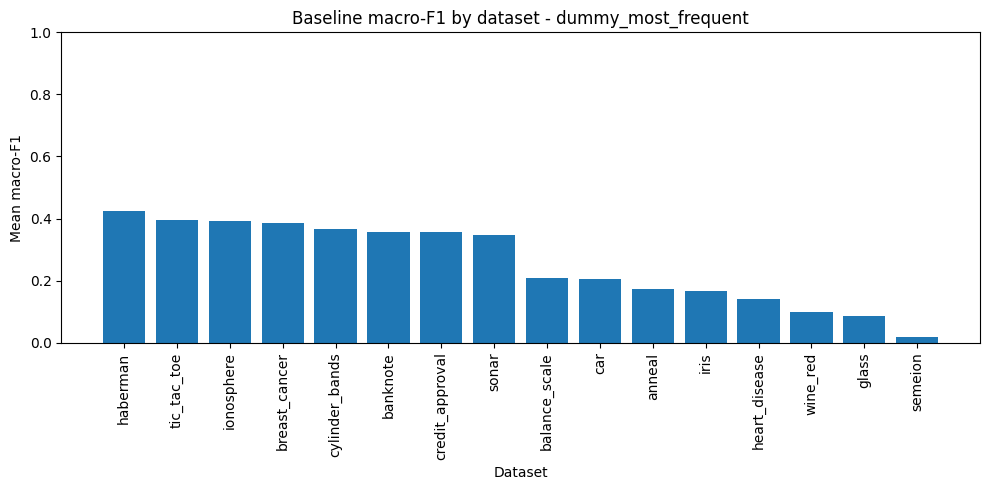

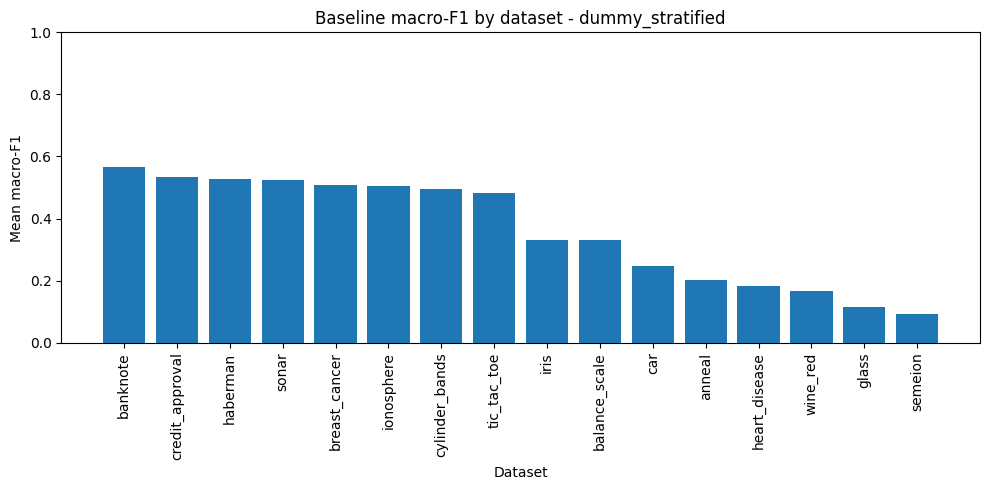

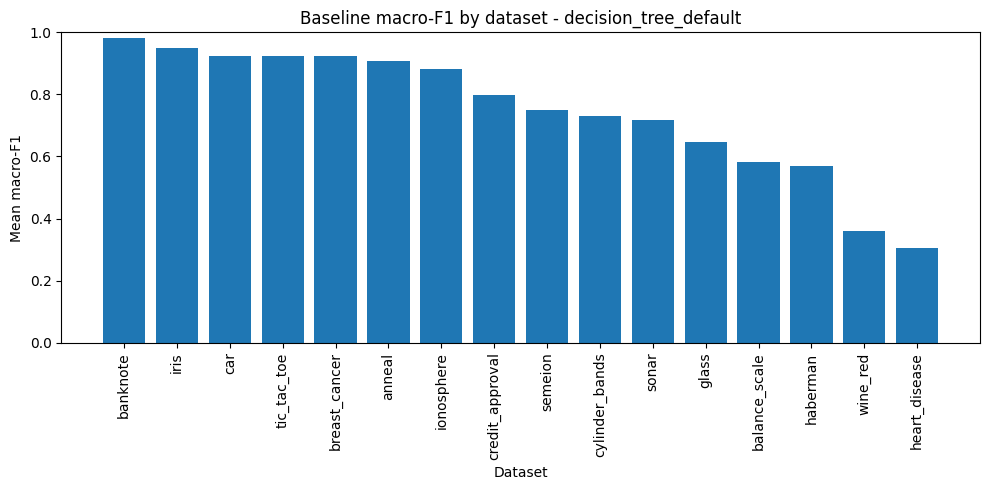

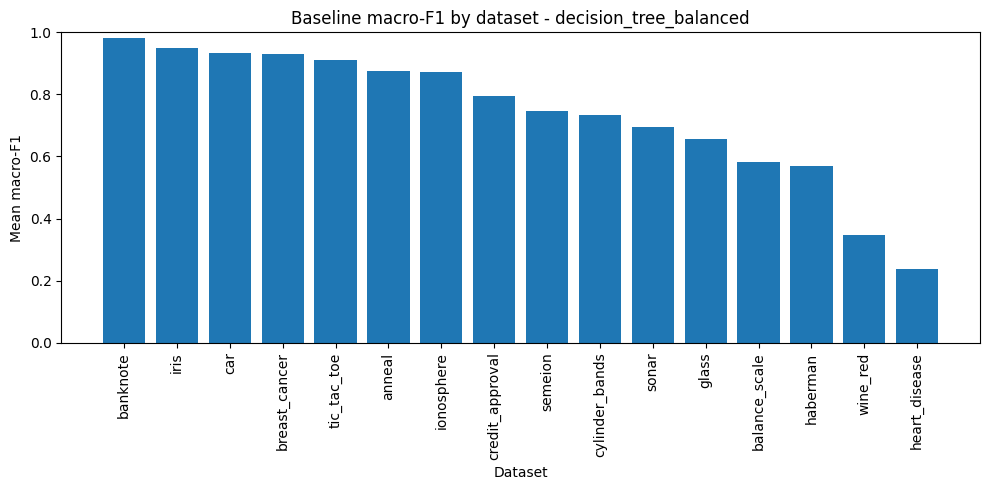

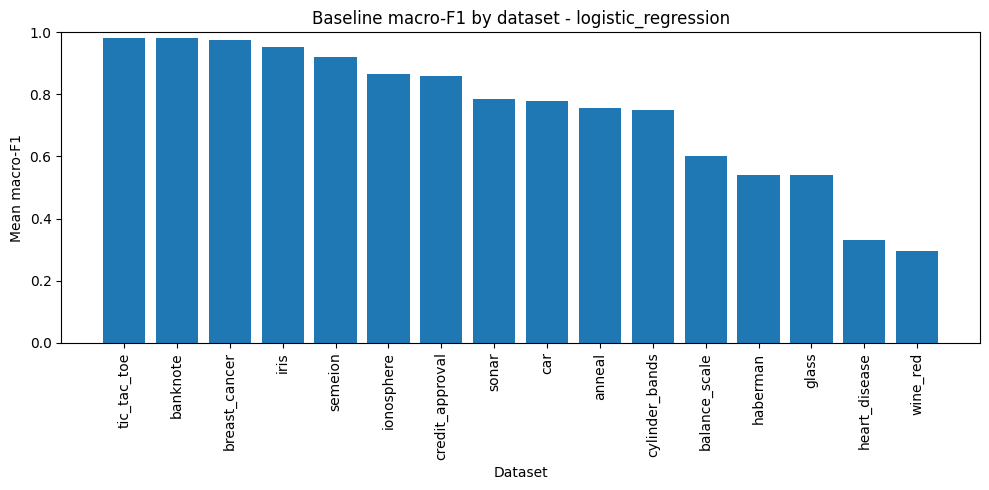

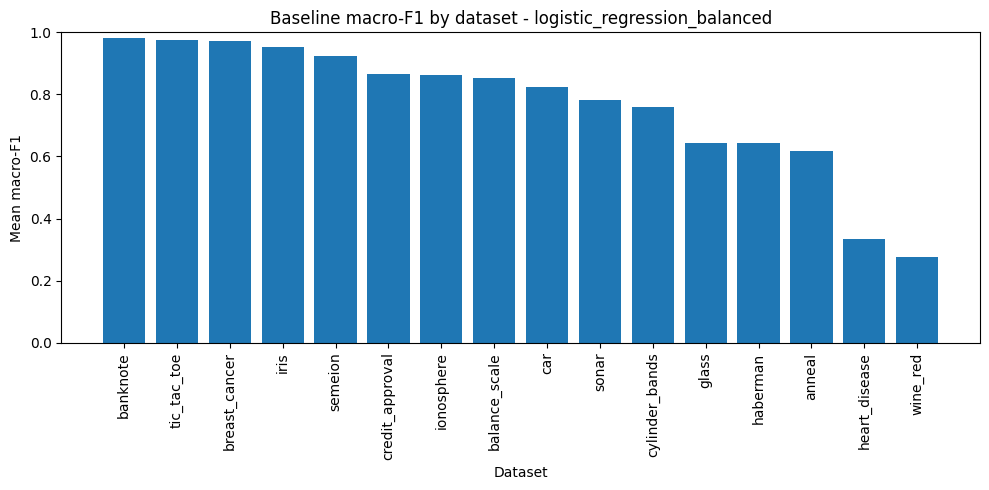

In [16]:
plot_df = baseline_df.dropna(subset=["f1_macro_mean"])
for model_name in plot_df["model"].unique():
    temp = plot_df[plot_df["model"] == model_name].sort_values("f1_macro_mean", ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(temp["dataset"], temp["f1_macro_mean"])
    plt.title(f"Baseline macro-F1 by dataset - {model_name}")
    plt.xlabel("Dataset")
    plt.ylabel("Mean macro-F1")
    plt.xticks(rotation=90)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


In [17]:
# ============================================================
# Computational characteristics by dataset
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Keep successful, non-dummy baseline evaluations
# ------------------------------------------------------------
#
# IMPORTANT:
# In baseline_df, successful evaluations store error as "".
# Failed/skipped evaluations store an error message.
# Therefore, filtering only with error.isna() removes all successful rows.

computational_source_df = baseline_df.copy()

if "error" in computational_source_df.columns:
    error_text = computational_source_df["error"].fillna("").astype(str).str.strip()
    computational_source_df = computational_source_df[
        error_text.eq("")
    ].copy()

computational_source_df = computational_source_df[
    ~computational_source_df["model"]
    .astype(str)
    .str.startswith("dummy")
].copy()

# Keep only rows with an actual runtime measurement.
computational_source_df = computational_source_df[
    computational_source_df["runtime_seconds"].notna()
].copy()


# ------------------------------------------------------------
# 2. Runtime across all successful non-dummy baseline models
# ------------------------------------------------------------

runtime_df = (
    computational_source_df
    .groupby("dataset", as_index=False)
    .agg(
        baseline_runtime_seconds_mean=(
            "runtime_seconds",
            "mean",
        )
    )
)


# ------------------------------------------------------------
# 3. Structural complexity of decision-tree baselines
# ------------------------------------------------------------

tree_source_df = computational_source_df[
    computational_source_df["model"]
    .astype(str)
    .str.contains("tree", case=False, na=False)
].copy()

tree_complexity_df = (
    tree_source_df
    .groupby("dataset", as_index=False)
    .agg(
        mean_tree_nodes=(
            "mean_tree_nodes",
            "mean",
        ),
        mean_tree_depth=(
            "mean_tree_depth",
            "mean",
        ),
        mean_tree_leaves=(
            "mean_tree_leaves",
            "mean",
        ),
    )
)


# ------------------------------------------------------------
# 4. Combine runtime and tree-complexity indicators
# ------------------------------------------------------------

computational_characteristics_df = (
    runtime_df
    .merge(
        tree_complexity_df,
        on="dataset",
        how="outer",
    )
)

# Optional audit: useful to confirm that the burden inputs exist.
print(
    "Computational rows used:",
    len(computational_source_df),
    "| datasets:",
    computational_characteristics_df["dataset"].nunique()
)

display(computational_characteristics_df)


Computational rows used: 64 | datasets: 16


,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves
0,anneal,0.138458,130.133333,18.600000,65.566667
1,balance_scale,0.031972,262.866667,11.333333,131.933333
2,banknote,0.032300,54.466667,7.500000,27.733333
3,breast_cancer,0.037302,37.266667,6.800000,19.133333
4,car,0.048855,211.133333,13.533333,106.066667
5,credit_approval,0.049729,154.533333,12.766667,77.766667
6,cylinder_bands,0.077280,119.400000,14.566667,60.200000
7,glass,0.032138,83.666667,10.500000,42.333333
8,haberman,0.026625,169.533333,15.166667,85.266667
9,heart_disease,0.031906,167.533333,11.833333,84.266667


## 13. Predictive difficulty, strategy sensitivity, and computational burden

The primary difficulty category is based on predictive difficulty only. Strategy sensitivity and computational burden are retained as separate experimental-profile dimensions.

# Multi-Dimensional Dataset Characterization

The code constructs a multi-dimensional profile for each dataset. The main predictive-difficulty label is derived exclusively from the average predictive performance of the evaluated decision-tree configurations. Cross-validation variability, strategy sensitivity, and computational burden are retained as independent descriptive dimensions and do not affect the Easy/Intermediate/Hard classification.

---

## 1. Min-Max Normalization

For any dataset-level indicator $x_d$, the code applies min-max normalization:

$$
z(x_d)
=
\frac{x_d-\min_i x_i}
{\max_i x_i-\min_i x_i}
$$

where the minimum and maximum are calculated across all valid datasets.

If all datasets have the same value for the indicator, the normalized value is set to zero.

---

## 2. Predictive Difficulty

Let

$$
\overline{F}_d
$$

denote `baseline_macro_f1_mean`, i.e., the average macro-F1 obtained for dataset $D_d$ across the decision-tree configurations used for characterization.

The predictive error is defined as

$$
E_d = 1-\overline{F}_d
$$

Therefore:

- high macro-F1 $\rightarrow$ low predictive error,
- low macro-F1 $\rightarrow$ high predictive error.

The predictive-difficulty score is then obtained by min-max normalizing this predictive error:

$$
D_d^{\mathrm{pred}}
=
z(E_d)
$$

Equivalently,

$$
D_d^{\mathrm{pred}}
=
\frac{
E_d-\min_i E_i
}{
\max_i E_i-\min_i E_i
}
$$

Thus,

$$
D_d^{\mathrm{pred}} \in [0,1]
$$

where lower values indicate easier datasets and higher values indicate harder datasets.

### Important

The current implementation does **not** use a weighted combination of predictive error and cross-validation variability.

In particular, it does **not** calculate

$$
0.70z(E_d)+0.30z(V_d)
$$

Instead, predictive difficulty is determined only by normalized predictive error:

$$
\boxed{
D_d^{\mathrm{pred}} = z(E_d)
}
$$

Cross-validation variability is computed separately.

---

## 3. Cross-Validation Variability

Cross-validation variability is represented by $V_d$, corresponding to `mean_model_cv_f1_std`.

The code also calculates its normalized form:

$$
D_d^{\mathrm{CV}}
=
z(V_d)
$$

However, this quantity is used only as a descriptive dimension.

It does **not** modify

$$
D_d^{\mathrm{pred}}
$$

and it does not participate in the assignment of the Easy, Intermediate, or Hard labels.

The datasets are additionally divided into descriptive terciles:

- `low`
- `medium`
- `high`

according to their cross-validation variability.

---

## 4. Strategy Sensitivity

Strategy sensitivity is based on the performance spread between the best and worst decision-tree configurations.

Let

$$
S_d
=
F^{\max}_d-F^{\min}_d
$$

In the code, this corresponds to:

`baseline_macro_f1_spread`

The normalized strategy-sensitivity score is

$$
D_d^{\mathrm{sens}}
=
z(S_d)
$$

As with CV variability, strategy sensitivity is retained as an independent descriptive dimension and does not affect predictive-difficulty labels.

Datasets are also assigned descriptive levels:

- `low`
- `medium`
- `high`

---

## 5. Computational Burden

Computational burden combines two normalized components:

1. average runtime across the evaluated baseline models;
2. average number of nodes generated by the decision-tree baselines.

Let

$$
T_d
$$

denote the average baseline runtime and

$$
N_d
$$

the average number of tree nodes.

The code first calculates

$$
z(T_d)
$$

and

$$
z(N_d)
$$

The final computational-burden score is

$$
D_d^{\mathrm{comp}}
=
\frac{
z(T_d)+z(N_d)
}{2}
$$

If one of the two components is unavailable, the available component may still contribute to the mean. If both are unavailable, the computational-burden score is set to missing.

This dimension is also independent from predictive difficulty.

---

## 6. Easy, Intermediate, and Hard Assignment

The Easy/Intermediate/Hard labels are determined using the predictive-difficulty score:

$$
D_d^{\mathrm{pred}}
$$

Eligible datasets are sorted primarily by

$$
D_d^{\mathrm{pred}}
$$

in ascending order.

Because

$$
D_d^{\mathrm{pred}} = z(1-\overline{F}_d)
$$

this is equivalent to ordering datasets from higher predictive performance to lower predictive performance.

The sorting criteria used by the code are:

1. lower `predictive_difficulty_score`;
2. higher `baseline_macro_f1_mean`;
3. alphabetical dataset name as a deterministic tie-break.

The ordered datasets are then divided into three approximately equal groups:

$$
\text{Easy},
\quad
\text{Intermediate},
\quad
\text{Hard}
$$

Therefore:

$$
\text{Easy}
\rightarrow
\text{lowest predictive error}
$$

$$
\text{Intermediate}
\rightarrow
\text{middle predictive error}
$$

$$
\text{Hard}
\rightarrow
\text{highest predictive error}
$$

Datasets without valid predictive-difficulty information are assigned:

`review_separately`

Cross-validation variability, strategy sensitivity, and computational burden are **not used** when creating these three predictive-difficulty groups.

---

## 7. Monotonicity Audit

After assigning the three predictive-difficulty groups, the code calculates the mean macro-F1 within each subset:

$$
\overline{F}_{\mathrm{Easy}},
\qquad
\overline{F}_{\mathrm{Intermediate}},
\qquad
\overline{F}_{\mathrm{Hard}}
$$

It then verifies whether

$$
\overline{F}_{\mathrm{Easy}}
\geq
\overline{F}_{\mathrm{Intermediate}}
\geq
\overline{F}_{\mathrm{Hard}}
$$

If this relationship holds, the variable

`is_monotonic_f1`

is set to `True`.

Otherwise, it is set to `False`.

The code only **checks** this condition. It does not automatically modify or reorder the subsets if monotonicity is not satisfied.

---

## 8. Final Dataset Profile

Each dataset therefore receives the following information:

| Dimension | Definition | Affects Easy/Intermediate/Hard? |
|---|---|---|
| Predictive difficulty | $z(1-\overline{F}_d)$ | **Yes** |
| CV variability | $z(V_d)$ | No |
| Strategy sensitivity | $z(S_d)$ | No |
| Computational burden | $\frac{z(T_d)+z(N_d)}{2}$ | No |

The central predictive-difficulty formulation implemented in the code is therefore:

$$
\boxed{
E_d = 1-\overline{F}_d
}
$$

followed by

$$
\boxed{
D_d^{\mathrm{pred}}
=
z(E_d)
}
$$

and the Easy/Intermediate/Hard subsets are obtained by ranking datasets according to this score and dividing the ordered benchmark into three approximately equal groups.

In [18]:
# 13. Multi-dimensional dataset profile
# =========================

def minmax_normalize(series):
    series = pd.to_numeric(series, errors="coerce")

    if series.notna().sum() == 0:
        return pd.Series(np.nan, index=series.index)

    min_val = series.min()
    max_val = series.max()

    if np.isclose(max_val, min_val):
        return pd.Series(0.0, index=series.index)

    return (series - min_val) / (max_val - min_val)


dataset_profile_df = baseline_characteristics_df.copy()


# ============================================================
# 1. Predictive difficulty
# ============================================================
#
# baseline_macro_f1_mean is already the average macro-F1 across
# the decision tree configurations selected for characterization.
#
# Therefore, predictive difficulty is determined only by the
# average performance of the decision tree family.

dataset_profile_df["predictive_error"] = (
    1.0 - dataset_profile_df["baseline_macro_f1_mean"]
)

dataset_profile_df["predictive_difficulty_score"] = minmax_normalize(
    dataset_profile_df["predictive_error"]
)


# ============================================================
# 2. CV variability
# ============================================================
#
# CV variability is retained as a separate descriptive dimension.
# It does not influence the Easy/Intermediate/Hard label.

dataset_profile_df["cv_variability"] = (
    dataset_profile_df["mean_model_cv_f1_std"]
)

dataset_profile_df["cv_variability_score"] = minmax_normalize(
    dataset_profile_df["cv_variability"]
)


# ============================================================
# 3. Strategy sensitivity
# ============================================================
#
# Strategy sensitivity represents the performance difference
# between the best and worst decision tree configurations.
# Dummy classifiers are not included in this spread.

dataset_profile_df["strategy_sensitivity"] = (
    dataset_profile_df["baseline_macro_f1_spread"]
)

dataset_profile_df["strategy_sensitivity_score"] = minmax_normalize(
    dataset_profile_df["strategy_sensitivity"]
)

# Remove previous incomplete computational columns, if present
computational_columns = [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "runtime_burden_score",
    "tree_size_burden_score",
    "computational_burden_score",
]

dataset_profile_df = dataset_profile_df.drop(
    columns=[
        column
        for column in computational_columns
        if column in dataset_profile_df.columns
    ],
    errors="ignore",
)

dataset_profile_df = dataset_profile_df.merge(
    computational_characteristics_df,
    on="dataset",
    how="left",
)


# ============================================================
# Descriptive profiles for variability and strategy sensitivity
# ============================================================
#
# These labels are independent from predictive difficulty.
# They describe the type of experimental challenge presented by
# each dataset, but they do not affect the Easy/Intermediate/Hard
# predictive-difficulty classification.

def assign_descriptive_terciles(df, value_col):
    """
    Divide valid datasets into low, medium, and high groups based on
    one descriptive dimension. Missing values are labeled separately.
    """

    labels = pd.Series(
        "review_separately",
        index=df.index,
        dtype="object",
    )

    valid = df[value_col].notna()

    if valid.sum() == 0:
        return labels

    ranked_indices = (
        df.loc[valid]
        .sort_values(
            [value_col, "dataset"],
            ascending=[True, True],
        )
        .index
        .to_numpy()
    )

    thirds = np.array_split(ranked_indices, 3)

    for label, indices in zip(
        ["low", "medium", "high"],
        thirds,
    ):
        labels.loc[indices] = label

    return labels


dataset_profile_df["cv_variability_level"] = (
    assign_descriptive_terciles(
        dataset_profile_df,
        "cv_variability",
    )
)

dataset_profile_df["strategy_sensitivity_level"] = (
    assign_descriptive_terciles(
        dataset_profile_df,
        "strategy_sensitivity",
    )
)


# ============================================================
# 4. Computational burden
# ============================================================
#
# Computational burden is kept as an optional complementary
# dimension. It is calculated from:
#   1. mean baseline runtime across successful non-dummy models; and
#   2. mean decision-tree node count across successful tree baselines.
#
# This does not affect predictive difficulty, CV variability,
# or strategy sensitivity.

runtime_column = "baseline_runtime_seconds_mean"
tree_size_column = "mean_tree_nodes"

if runtime_column in dataset_profile_df.columns:
    dataset_profile_df["runtime_burden_score"] = minmax_normalize(
        dataset_profile_df[runtime_column]
    )
else:
    dataset_profile_df["runtime_burden_score"] = np.nan
    print(
        f"[INFO] '{runtime_column}' is not available. "
        "Runtime burden was not calculated."
    )

if tree_size_column in dataset_profile_df.columns:
    dataset_profile_df["tree_size_burden_score"] = minmax_normalize(
        dataset_profile_df[tree_size_column]
    )
else:
    dataset_profile_df["tree_size_burden_score"] = np.nan
    print(
        f"[INFO] '{tree_size_column}' is not available. "
        "Tree-size burden was not calculated."
    )

dataset_profile_df["computational_burden_score"] = (
    dataset_profile_df[
        [
            "runtime_burden_score",
            "tree_size_burden_score",
        ]
    ]
    .mean(axis=1, skipna=True)
)

# When both components are unavailable, pandas may produce NaN.
dataset_profile_df.loc[
    dataset_profile_df[
        [
            "runtime_burden_score",
            "tree_size_burden_score",
        ]
    ].isna().all(axis=1),
    "computational_burden_score",
] = np.nan


# ============================================================
# 5. Predictive-difficulty labels
# ============================================================
#
# Datasets are ranked using predictive difficulty only.
#
# Lower predictive-difficulty score = easier dataset.
# Higher predictive-difficulty score = harder dataset.

def tercile_labels_from_predictive_score(df):
    valid = (
        df["predictive_difficulty_score"].notna()
        & df["baseline_macro_f1_mean"].notna()
    )

    labels = pd.Series(
        "review_separately",
        index=df.index,
        dtype="object",
    )

    if valid.sum() == 0:
        return labels

    ranked = df.loc[valid].sort_values(
        [
            "predictive_difficulty_score",
            "baseline_macro_f1_mean",
            "dataset",
        ],
        ascending=[
            True,   # Low predictive error first
            False,  # High macro-F1 first
            True,   # Deterministic tie-break
        ],
    )

    thirds = np.array_split(
        ranked.index.to_numpy(),
        3,
    )

    for label, indices in zip(
        ["easy", "intermediate", "hard"],
        thirds,
    ):
        labels.loc[indices] = label

    return labels


dataset_profile_df["predictive_difficulty_label"] = (
    tercile_labels_from_predictive_score(dataset_profile_df)
)

dataset_profile_df["difficulty_label_assignment_note"] = (
    "Predictive-difficulty labels were assigned using the average "
    "macro-F1 across decision tree configurations. CV variability, "
    "strategy sensitivity, and computational burden were retained "
    "as separate descriptive dimensions."
)


# ============================================================
# 6. Monotonicity audit
# ============================================================

ordered_labels = [
    "easy",
    "intermediate",
    "hard",
]

predictive_monotonicity_df = (
    dataset_profile_df[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ordered_labels
        )
    ]
    .groupby(
        "predictive_difficulty_label",
        observed=True,
    )
    .agg(
        n_datasets=("dataset", "nunique"),
        mean_tree_macro_f1=("baseline_macro_f1_mean", "mean"),
        min_tree_macro_f1=("baseline_macro_f1_mean", "min"),
        max_tree_macro_f1=("baseline_macro_f1_mean", "max"),
        mean_cv_variability=("cv_variability", "mean"),
        mean_strategy_sensitivity=("strategy_sensitivity", "mean"),
        mean_computational_burden=(
            "computational_burden_score",
            "mean",
        ),
    )
    .reindex(ordered_labels)
    .reset_index()
)


valid_group_means = (
    predictive_monotonicity_df["mean_tree_macro_f1"]
    .dropna()
    .to_numpy()
)

is_monotonic_f1 = (
    len(valid_group_means) == 3
    and valid_group_means[0] >= valid_group_means[1]
    and valid_group_means[1] >= valid_group_means[2]
)

print(
    "Monotonic predictive difficulty:",
    is_monotonic_f1,
)


# ============================================================
# 7. Export and display
# ============================================================

dataset_profile_df.to_csv(
    output_dir / "dataset_experimental_profile.csv",
    index=False,
)

predictive_monotonicity_df.to_csv(
    output_dir / "predictive_difficulty_monotonicity_check.csv",
    index=False,
)


display(predictive_monotonicity_df)

display(
    dataset_profile_df[
        [
            "dataset",

            # Main difficulty construct
            "baseline_macro_f1_mean",
            "predictive_difficulty_score",
            "predictive_difficulty_label",

            # Independent descriptive dimension 1
            "cv_variability",
            "cv_variability_score",
            "cv_variability_level",

            # Independent descriptive dimension 2
            "strategy_sensitivity",
            "strategy_sensitivity_score",
            "strategy_sensitivity_level",

            # Complementary computational dimension
            "computational_burden_score",
        ]
    ].sort_values(
        [
            "predictive_difficulty_label",
            "predictive_difficulty_score",
            "dataset",
        ]
    )
)


Monotonic predictive difficulty: True


,predictive_difficulty_label,n_datasets,mean_tree_macro_f1,min_tree_macro_f1,max_tree_macro_f1,mean_cv_variability,mean_strategy_sensitivity,mean_computational_burden
0,easy,6,0.932395,0.890766,0.982051,0.033298,0.010788,0.112191
1,intermediate,5,0.772403,0.704799,0.878116,0.042691,0.008607,0.239430
2,hard,5,0.485952,0.271637,0.651159,0.051111,0.018328,0.205374


,dataset,baseline_macro_f1_mean,predictive_difficulty_score,predictive_difficulty_label,cv_variability,cv_variability_score,cv_variability_level,strategy_sensitivity,strategy_sensitivity_score,strategy_sensitivity_level,computational_burden_score
2,banknote,0.982051,0.000000,easy,0.007207,0.000000,low,0.000488,0.007308,low,0.039348
11,iris,0.948693,0.046956,easy,0.043535,0.426517,medium,0.000000,0.000000,low,0.006311
4,car,0.928424,0.075488,easy,0.025976,0.220365,low,0.008930,0.133628,medium,0.182891
3,breast_cancer,0.927398,0.076932,easy,0.024528,0.203361,low,0.008776,0.131324,medium,0.036739
14,tic_tac_toe,0.917039,0.091513,easy,0.022522,0.179809,low,0.012881,0.192755,high,0.109879
0,anneal,0.890766,0.128497,easy,0.076020,0.807903,high,0.033654,0.503623,high,0.297975
7,glass,0.651159,0.465774,hard,0.092382,1.000000,high,0.011347,0.169806,high,0.059839
1,balance_scale,0.583084,0.561598,hard,0.026579,0.227437,low,0.001365,0.020424,low,0.187191
8,haberman,0.570006,0.580007,hard,0.056230,0.575555,high,0.001079,0.016153,low,0.110383
15,wine_red,0.353872,0.884244,hard,0.032364,0.295357,medium,0.011024,0.164974,medium,0.550313


In [19]:
descriptive_profile_table = dataset_profile_df[
    [
        "dataset",
        "baseline_macro_f1_mean",
        "predictive_difficulty_label",
        "cv_variability",
        "cv_variability_level",
        "strategy_sensitivity",
        "strategy_sensitivity_level",
        "computational_burden_score",
    ]
].copy()

descriptive_profile_table = descriptive_profile_table.rename(
    columns={
        "baseline_macro_f1_mean": "mean_tree_macro_f1",
        "predictive_difficulty_label": "predictive_difficulty",
    }
)

descriptive_profile_table.to_csv(
    output_dir / "dataset_descriptive_profiles.csv",
    index=False,
)

display(
    descriptive_profile_table.sort_values(
        [
            "predictive_difficulty",
            "mean_tree_macro_f1",
        ],
        ascending=[True, False],
    )
)

,dataset,mean_tree_macro_f1,predictive_difficulty,cv_variability,cv_variability_level,strategy_sensitivity,strategy_sensitivity_level,computational_burden_score
2,banknote,0.982051,easy,0.007207,low,0.000488,low,0.039348
11,iris,0.948693,easy,0.043535,medium,0.000000,low,0.006311
4,car,0.928424,easy,0.025976,low,0.008930,medium,0.182891
3,breast_cancer,0.927398,easy,0.024528,low,0.008776,medium,0.036739
14,tic_tac_toe,0.917039,easy,0.022522,low,0.012881,high,0.109879
0,anneal,0.890766,easy,0.076020,high,0.033654,high,0.297975
7,glass,0.651159,hard,0.092382,high,0.011347,high,0.059839
1,balance_scale,0.583084,hard,0.026579,low,0.001365,low,0.187191
8,haberman,0.570006,hard,0.056230,high,0.001079,low,0.110383
15,wine_red,0.353872,hard,0.032364,medium,0.011024,medium,0.550313


## 14. Dataset similarity based on class distributions

Uses Jensen-Shannon distance between class distributions. This is a rough comparison because datasets may have different numbers of classes.

In [20]:
names = list(loaded.keys())
max_classes = max(len(np.unique(loaded[name]["y"])) for name in names)

class_vectors = {}
for name in names:
    y = loaded[name]["y"]
    counts = np.bincount(y, minlength=max_classes)
    class_vectors[name] = counts / counts.sum()

similarity_matrix = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        similarity_matrix.loc[a, b] = jensenshannon(class_vectors[a], class_vectors[b])

similarity_matrix.to_csv(output_dir / "class_distribution_js_distance.csv")
similarity_matrix


,abalone,anneal,arrhythmia,bridges,balance_scale,car,cylinder_bands,glass,heart_disease,ionosphere,semeion,sonar,tic_tac_toe,breast_cancer,wine_red,iris,haberman,parkinsons,banknote,credit_approval
abalone,0.000000,0.756184,0.722341,0.749455,0.708020,0.788219,0.711055,0.711710,0.743374,0.706102,0.749452,0.720994,0.705178,0.707132,0.782589,0.723265,0.745300,0.739883,0.723156,0.712943
anneal,0.756184,0.000000,0.737804,0.608591,0.363840,0.294972,0.719662,0.579297,0.550975,0.716556,0.587373,0.726266,0.715996,0.717189,0.332094,0.457820,0.743636,0.803070,0.727751,0.720884
arrhythmia,0.722341,0.737804,0.000000,0.592111,0.646250,0.627196,0.459309,0.470979,0.422770,0.482947,0.496202,0.423523,0.487891,0.477646,0.756336,0.511231,0.379487,0.771652,0.417403,0.451422
bridges,0.749455,0.608591,0.592111,0.000000,0.607028,0.620814,0.637186,0.466595,0.532851,0.640019,0.396738,0.635143,0.640734,0.639298,0.579924,0.576199,0.641143,0.784983,0.635161,0.636476
balance_scale,0.708020,0.363840,0.646250,0.607028,0.000000,0.383795,0.477357,0.448831,0.487118,0.464594,0.606179,0.504679,0.462337,0.467164,0.560585,0.229672,0.571101,0.809592,0.510722,0.482433
car,0.788219,0.294972,0.627196,0.620814,0.383795,0.000000,0.641551,0.531100,0.445450,0.651032,0.599801,0.627987,0.653074,0.648867,0.464923,0.343209,0.612047,0.806259,0.625748,0.638485
cylinder_bands,0.711055,0.719662,0.459309,0.637186,0.477357,0.641551,0.000000,0.355760,0.392572,0.045853,0.649102,0.078954,0.055029,0.035872,0.782570,0.367074,0.226339,0.815284,0.094330,0.016199
glass,0.711710,0.579297,0.470979,0.466595,0.448831,0.531100,0.355760,0.000000,0.284429,0.362352,0.465541,0.355548,0.364221,0.360524,0.595333,0.353211,0.392010,0.793042,0.357165,0.354554
heart_disease,0.743374,0.550975,0.422770,0.532851,0.487118,0.445450,0.392572,0.284429,0.000000,0.416398,0.517074,0.358461,0.421458,0.410999,0.549894,0.324402,0.327692,0.798535,0.353042,0.384799
ionosphere,0.706102,0.716556,0.482947,0.640019,0.464594,0.651032,0.045853,0.362352,0.416398,0.000000,0.650953,0.124574,0.009189,0.009990,0.781821,0.374799,0.270783,0.815375,0.139873,0.062028


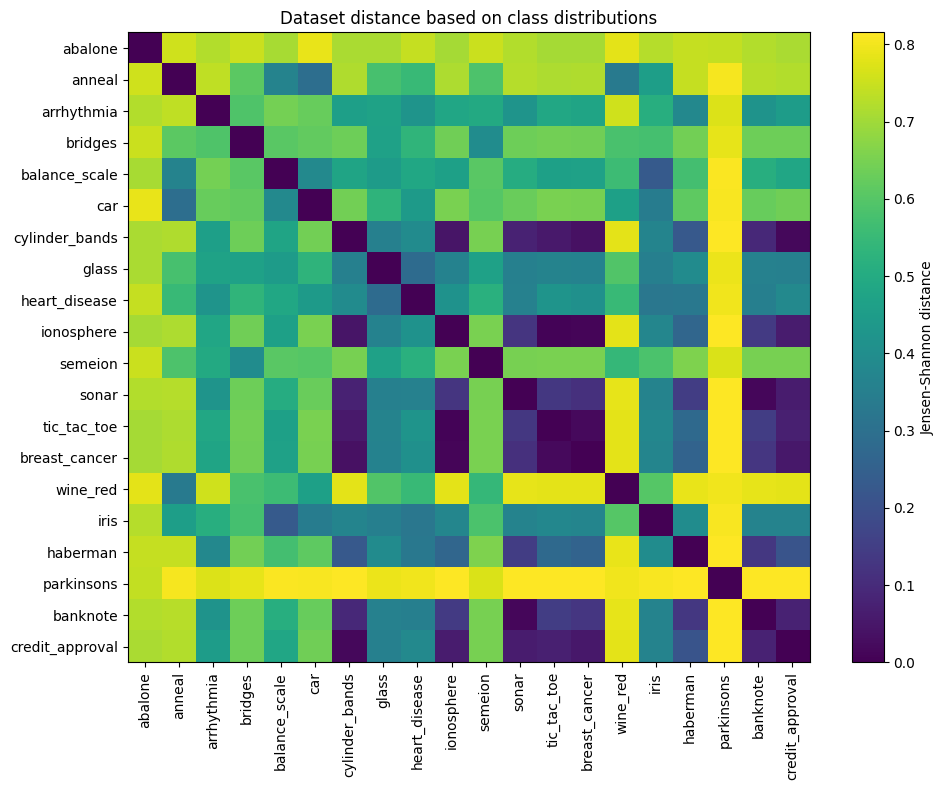

In [21]:
plt.figure(figsize=(10, 8))
plt.imshow(similarity_matrix.astype(float), aspect="auto")
plt.colorbar(label="Jensen-Shannon distance")
plt.xticks(range(len(names)), names, rotation=90)
plt.yticks(range(len(names)), names)
plt.title("Dataset distance based on class distributions")
plt.tight_layout()
plt.show()


## 15. Thesis-oriented interpretation table

This final table merges the most useful indicators for discussion.

In [22]:
tree_baselines = baseline_df[
    baseline_df["model"].isin(["decision_tree_default", "decision_tree_balanced"])
].pivot_table(
    index="dataset",
    columns="model",
    values=["f1_macro_mean", "f1_macro_std"],
    aggfunc="first",
)

tree_baselines.columns = [
    f"{model}_{metric}".replace("decision_tree_", "tree_")
    for metric, model in tree_baselines.columns
]
tree_baselines = tree_baselines.reset_index()

profile_columns = [
    "dataset",

    # Predictive difficulty
    "predictive_error",
    "predictive_difficulty_score",
    "predictive_difficulty_label",

    # Independent descriptive dimensions
    "cv_variability_score",
    "cv_variability_level",
    "strategy_sensitivity",
    "strategy_sensitivity_score",
    "strategy_sensitivity_level",

    # Computational burden
    "runtime_burden_score",
    "tree_size_burden_score",
    "computational_burden_score",

    # Methodological note
    "difficulty_label_assignment_note",
]

final_interpretation_df = (
    summary_df
    .merge(
        tree_baselines,
        on="dataset",
        how="left",
    )
    .merge(
        cv_audit_df[
            [
                "dataset",
                "comparable_cv",
                "cv_issue",
                "min_class_count",
            ]
        ],
        on="dataset",
        how="left",
    )
    .merge(
        baseline_characteristics_df,
        on="dataset",
        how="left",
    )
    .merge(
        dataset_profile_df[profile_columns],
        on="dataset",
        how="left",
    )
)

# Backward-compatible names for the default tree baseline.
if "tree_default_f1_macro_mean" in final_interpretation_df.columns:
    final_interpretation_df["baseline_tree_f1_mean"] = final_interpretation_df["tree_default_f1_macro_mean"]
if "tree_default_f1_macro_std" in final_interpretation_df.columns:
    final_interpretation_df["baseline_tree_f1_std"] = final_interpretation_df["tree_default_f1_macro_std"]

# Backward-compatible difficulty column, now explicitly predictive rather than
# broad experimental challenge.
final_interpretation_df["tree_difficulty_revised"] = final_interpretation_df["predictive_difficulty_label"]

final_interpretation_df["possible_issue"] = ""
final_interpretation_df.loc[final_interpretation_df["imbalance_ratio"] > 2, "possible_issue"] += "class imbalance; "
final_interpretation_df.loc[final_interpretation_df["missing_pct"] > 5, "possible_issue"] += "missing values; "
final_interpretation_df.loc[final_interpretation_df["samples_per_feature"] < 10, "possible_issue"] += "low samples/features ratio; "
final_interpretation_df.loc[final_interpretation_df["comparable_cv"] == False, "possible_issue"] += "not eligible for fixed 5-fold CV; "
final_interpretation_df.loc[final_interpretation_df["cv_variability"] > 0.10, "possible_issue"] += "high within-model CV variability; "
final_interpretation_df.loc[final_interpretation_df["baseline_macro_f1_spread"] > 0.20, "possible_issue"] += "large strategy sensitivity; "
final_interpretation_df.loc[final_interpretation_df["computational_burden_score"] > 0.66, "possible_issue"] += "high computational burden; "

final_interpretation_df["possible_issue"] = final_interpretation_df["possible_issue"].replace("", "none obvious")

final_interpretation_df.to_csv(output_dir / "thesis_dataset_interpretation_summary.csv", index=False)
final_interpretation_df.sort_values(["predictive_difficulty_label", "baseline_macro_f1_mean"], ascending=[True, False])


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature,...,strategy_sensitivity_score,strategy_sensitivity_level,runtime_burden_score,tree_size_burden_score,computational_burden_score,difficulty_label_assignment_note,baseline_tree_f1_mean,baseline_tree_f1_std,tree_difficulty_revised,possible_issue
4,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000,...,0.007308,low,0.021890,0.056806,0.039348,Predictive-difficulty labels were assigned usi...,0.981807,0.008156,easy,none obvious
14,iris,150,4,4,0,3,0.000000,1.584963,1.000000,37.500000,...,0.000000,low,0.012622,0.000000,0.006311,Predictive-difficulty labels were assigned usi...,0.948693,0.043535,easy,none obvious
7,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000,...,0.133628,medium,0.085741,0.280042,0.182891,Predictive-difficulty labels were assigned usi...,0.923959,0.032338,easy,class imbalance;
5,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667,...,0.131324,medium,0.041180,0.032298,0.036739,Predictive-difficulty labels were assigned usi...,0.923010,0.031058,easy,none obvious
18,tic_tac_toe,958,9,0,9,2,0.000000,0.930954,1.885542,106.444444,...,0.192755,high,0.043260,0.176499,0.109879,Predictive-difficulty labels were assigned usi...,0.923480,0.020787,easy,none obvious
1,anneal,798,38,16,22,5,64.938662,1.190925,76.000000,21.000000,...,0.503623,high,0.431326,0.164624,0.297975,Predictive-difficulty labels were assigned usi...,0.907593,0.070142,easy,class imbalance; missing values;
10,glass,214,9,9,0,6,0.000000,2.176534,8.444444,23.777778,...,0.169806,high,0.021264,0.098414,0.059839,Predictive-difficulty labels were assigned usi...,0.645485,0.099260,hard,class imbalance;
3,balance_scale,625,4,4,0,3,0.000000,1.318116,5.877551,156.250000,...,0.020424,low,0.020625,0.353757,0.187191,Predictive-difficulty labels were assigned usi...,0.583766,0.029132,hard,class imbalance;
11,haberman,306,3,3,0,2,0.000000,0.833765,2.777778,102.000000,...,0.016153,low,0.000000,0.220766,0.110383,Predictive-difficulty labels were assigned usi...,0.569466,0.064485,hard,class imbalance;
19,wine_red,1599,11,11,0,6,0.000000,1.709062,68.100000,145.363636,...,0.164974,medium,0.100627,1.000000,0.550313,Predictive-difficulty labels were assigned usi...,0.359384,0.038939,hard,class imbalance;


Justify why each dataset may affect the GA differently:

- The primary `predictive_difficulty_label` is driven by baseline macro-F1 and within-model CV instability.
- `strategy_sensitivity` reports algorithm-to-algorithm disagreement and is not used to dominate the main difficulty label.
- `computational_burden_score` reports runtime/tree-size pressure and is also separate from the main difficulty label.
- Dataset imbalance can affect macro-F1 and make some datasets harder.
- Missing values make missing-value handling genes more relevant.
- Strong univariate feature importance may indicate that simple trees can already perform well.
- High `cv_variability` means fold-to-fold instability within models is large.
- High `baseline_macro_f1_spread` means algorithms differ substantially on the dataset.
- Dataset differences help explain why SDD alone may encourage equal behavior without necessarily improving absolute F1.


In [23]:
# ============================================================
# Table for the article: predictive-difficulty ranking
# ============================================================

article_ranking_df = (
    dataset_profile_df.loc[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ["easy", "intermediate", "hard"]
        ),
        [
            "dataset",
            "baseline_macro_f1_mean",
            "predictive_error",
            "cv_variability_score",
            "predictive_difficulty_score",
            "predictive_difficulty_label",
        ],
    ]
    .sort_values(
        [
            "predictive_difficulty_score",
            "baseline_macro_f1_mean",
            "cv_variability_score",
        ],
        ascending=[True, False, True],
    )
    .copy()
)

# Names formatted for the paper
dataset_display_names = {
    "banknote": "Banknote Authentication",
    "breast_cancer": "Breast Cancer",
    "car": "Car Evaluation",
    "credit_approval": "Credit Approval",
    "cylinder_bands": "Cylinder Bands",
    "heart_disease": "Heart Disease",
    "tic_tac_toe": "Tic-Tac-Toe",
    "wine_red": "Wine Quality Red",
    "anneal": "Anneal",
    "balance_scale": "Balance Scale",
    "glass": "Glass",
    "haberman": "Haberman",
    "ionosphere": "Ionosphere",
    "iris": "Iris",
    "semeion": "Semeion",
    "sonar": "Sonar",
}

article_ranking_df["dataset"] = (
    article_ranking_df["dataset"]
    .map(dataset_display_names)
    .fillna(article_ranking_df["dataset"])
)

article_ranking_df["predictive_difficulty_label"] = (
    article_ranking_df["predictive_difficulty_label"]
    .str.capitalize()
)

article_ranking_df = article_ranking_df.rename(
    columns={
        "dataset": "Dataset",
        "baseline_macro_f1_mean": "Mean baseline macro-F1",
        "predictive_error": "Predictive error score",
        "cv_variability_score": "CV variability score",
        "predictive_difficulty_score": "Predictive difficulty score",
        "predictive_difficulty_label": "Final subset",
    }
)

numeric_columns = [
    "Mean baseline macro-F1",
    "Predictive error score",
    "CV variability score",
    "Predictive difficulty score",
]

article_ranking_df[numeric_columns] = (
    article_ranking_df[numeric_columns].round(4)
)

display(article_ranking_df)

latex_table = article_ranking_df.to_latex(
    index=False,
    escape=False,
    column_format="lrrrrl",
    caption=(
        "Predictive-difficulty ranking of the eligible datasets. "
        "The score combines normalized predictive error and "
        "cross-validation variability with weights of 0.70 and 0.30, "
        "respectively. Lower values indicate more favorable predictive behavior."
    ),
    label="tab:predictive_difficulty_ranking",
    position="t",
    float_format="%.4f",
)

latex_path = output_dir / "predictive_difficulty_ranking_table.tex"
latex_path.write_text(latex_table, encoding="utf-8")

print(latex_table)
print(f"\nSaved to: {latex_path}")


,Dataset,Mean baseline macro-F1,Predictive error score,CV variability score,Predictive difficulty score,Final subset
2,Banknote Authentication,0.9821,0.0179,0.0000,0.0000,Easy
11,Iris,0.9487,0.0513,0.4265,0.0470,Easy
4,Car Evaluation,0.9284,0.0716,0.2204,0.0755,Easy
3,Breast Cancer,0.9274,0.0726,0.2034,0.0769,Easy
14,Tic-Tac-Toe,0.9170,0.0830,0.1798,0.0915,Easy
0,Anneal,0.8908,0.1092,0.8079,0.1285,Easy
10,Ionosphere,0.8781,0.1219,0.2698,0.1463,Intermediate
5,Credit Approval,0.7977,0.2023,0.4561,0.2595,Intermediate
12,Semeion,0.7486,0.2514,0.1347,0.3286,Intermediate
6,Cylinder Bands,0.7328,0.2672,0.6023,0.3509,Intermediate


\begin{table}[t]
\caption{Predictive-difficulty ranking of the eligible datasets. The score combines normalized predictive error and cross-validation variability with weights of 0.70 and 0.30, respectively. Lower values indicate more favorable predictive behavior.}
\label{tab:predictive_difficulty_ranking}
\begin{tabular}{lrrrrl}
\toprule
Dataset & Mean baseline macro-F1 & Predictive error score & CV variability score & Predictive difficulty score & Final subset \\
\midrule
Banknote Authentication & 0.9821 & 0.0179 & 0.0000 & 0.0000 & Easy \\
Iris & 0.9487 & 0.0513 & 0.4265 & 0.0470 & Easy \\
Car Evaluation & 0.9284 & 0.0716 & 0.2204 & 0.0755 & Easy \\
Breast Cancer & 0.9274 & 0.0726 & 0.2034 & 0.0769 & Easy \\
Tic-Tac-Toe & 0.9170 & 0.0830 & 0.1798 & 0.0915 & Easy \\
Anneal & 0.8908 & 0.1092 & 0.8079 & 0.1285 & Easy \\
Ionosphere & 0.8781 & 0.1219 & 0.2698 & 0.1463 & Intermediate \\
Credit Approval & 0.7977 & 0.2023 & 0.4561 & 0.2595 & Intermediate \\
Semeion & 0.7486 & 0.2514 & 0.134

In [24]:
# ============================================================
# Computational-burden score
# ============================================================

def minmax_normalize(series):
    series = pd.to_numeric(series, errors="coerce")

    minimum = series.min(skipna=True)
    maximum = series.max(skipna=True)

    if pd.isna(minimum) or pd.isna(maximum):
        return pd.Series(
            np.nan,
            index=series.index,
            dtype=float,
        )

    if np.isclose(maximum, minimum):
        return pd.Series(
            0.0,
            index=series.index,
            dtype=float,
        )

    return (series - minimum) / (maximum - minimum)


dataset_profile_df["runtime_burden_score"] = minmax_normalize(
    dataset_profile_df["baseline_runtime_seconds_mean"]
)

dataset_profile_df["tree_size_burden_score"] = minmax_normalize(
    dataset_profile_df["mean_tree_nodes"]
)

dataset_profile_df["computational_burden_score"] = (
    dataset_profile_df[
        [
            "runtime_burden_score",
            "tree_size_burden_score",
        ]
    ]
    .mean(axis=1, skipna=True)
)

display(
    dataset_profile_df[
        [
            "dataset",
            "baseline_runtime_seconds_mean",
            "mean_tree_nodes",
            "mean_tree_depth",
            "mean_tree_leaves",
            "runtime_burden_score",
            "tree_size_burden_score",
            "computational_burden_score",
        ]
    ]
    .sort_values(
        "computational_burden_score",
        ascending=False,
    )
)

,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,runtime_burden_score,tree_size_burden_score,computational_burden_score
12,semeion,0.285904,438.200000,15.166667,219.600000,1.000000,0.603591,0.801795
15,wine_red,0.052715,716.400000,20.666667,358.700000,0.100627,1.000000,0.550313
0,anneal,0.138458,130.133333,18.600000,65.566667,0.431326,0.164624,0.297975
1,balance_scale,0.031972,262.866667,11.333333,131.933333,0.020625,0.353757,0.187191
4,car,0.048855,211.133333,13.533333,106.066667,0.085741,0.280042,0.182891
6,cylinder_bands,0.077280,119.400000,14.566667,60.200000,0.195371,0.149330,0.172351
5,credit_approval,0.049729,154.533333,12.766667,77.766667,0.089111,0.199392,0.144251
9,heart_disease,0.031906,167.533333,11.833333,84.266667,0.020371,0.217916,0.119144
8,haberman,0.026625,169.533333,15.166667,85.266667,0.000000,0.220766,0.110383
14,tic_tac_toe,0.037841,138.466667,10.933333,69.733333,0.043260,0.176499,0.109879


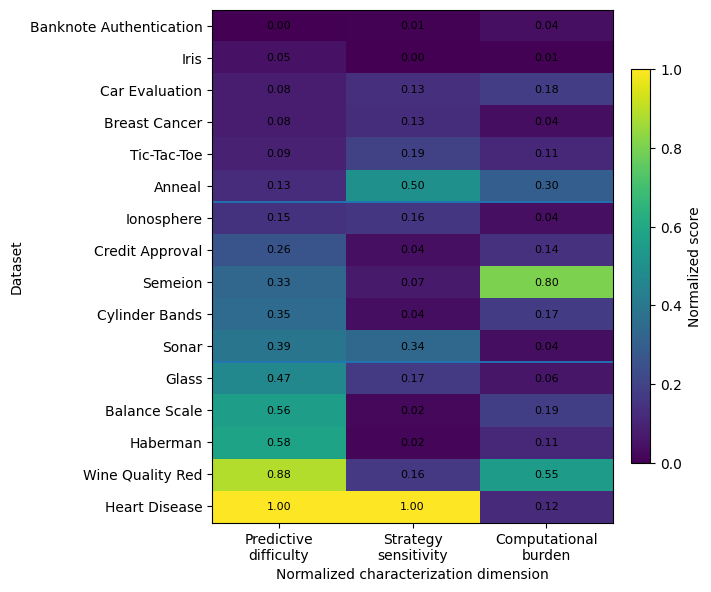

Saved to: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\dataset_statistics\subset_dimension_profiles.pdf


In [25]:

# ============================================================
# Multidimensional dataset-profile heatmap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


required_columns = [
    "dataset",
    "predictive_difficulty_score",
    "strategy_sensitivity_score",
    "computational_burden_score",
    "predictive_difficulty_label",
]

missing_columns = [
    column
    for column in required_columns
    if column not in dataset_profile_df.columns
]

if missing_columns:
    raise KeyError(
        "The following columns are required to generate the profile figure: "
        f"{missing_columns}"
    )


# Keep only datasets included in the final ranking
profile_plot_df = dataset_profile_df.loc[
    dataset_profile_df["predictive_difficulty_label"].isin(
        ["easy", "intermediate", "hard"]
    ),
    required_columns,
].copy()


# Explicit order of the subsets
label_order = {
    "easy": 0,
    "intermediate": 1,
    "hard": 2,
}

profile_plot_df["label_order"] = (
    profile_plot_df["predictive_difficulty_label"]
    .map(label_order)
)


# Sort first by subset and then by predictive-difficulty score
profile_plot_df = (
    profile_plot_df
    .sort_values(
        [
            "label_order",
            "predictive_difficulty_score",
        ],
        ascending=[True, True],
    )
    .reset_index(drop=True)
)


# Dataset names formatted for the paper
dataset_display_names = {
    "banknote": "Banknote Authentication",
    "breast_cancer": "Breast Cancer",
    "car": "Car Evaluation",
    "credit_approval": "Credit Approval",
    "cylinder_bands": "Cylinder Bands",
    "heart_disease": "Heart Disease",
    "tic_tac_toe": "Tic-Tac-Toe",
    "wine_red": "Wine Quality Red",
    "balance_scale": "Balance Scale",
    "anneal": "Anneal",
    "glass": "Glass",
    "haberman": "Haberman",
    "ionosphere": "Ionosphere",
    "iris": "Iris",
    "semeion": "Semeion",
    "sonar": "Sonar",
}

profile_plot_df["dataset_display"] = (
    profile_plot_df["dataset"]
    .map(dataset_display_names)
    .fillna(
        profile_plot_df["dataset"]
        .str.replace("_", " ")
        .str.title()
    )
)


dimension_columns = [
    "predictive_difficulty_score",
    "strategy_sensitivity_score",
    "computational_burden_score",
]

dimension_labels = [
    "Predictive\ndifficulty",
    "Strategy\nsensitivity",
    "Computational\nburden",
]

dimension_matrix = profile_plot_df[dimension_columns].to_numpy()


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

figure_height = max(5.5, 0.38 * len(profile_plot_df))

fig, ax = plt.subplots(
    figsize=(7.2, figure_height)
)

heatmap = ax.imshow(
    dimension_matrix,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(len(dimension_labels)))
ax.set_xticklabels(dimension_labels)

ax.set_yticks(np.arange(len(profile_plot_df)))
ax.set_yticklabels(profile_plot_df["dataset_display"])

ax.set_xlabel("Normalized characterization dimension")
ax.set_ylabel("Dataset")


# Add numerical values
for row_index in range(dimension_matrix.shape[0]):
    for column_index in range(dimension_matrix.shape[1]):
        value = dimension_matrix[row_index, column_index]

        if pd.notna(value):
            ax.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
            )


# Add horizontal separators between subsets
label_values = profile_plot_df["predictive_difficulty_label"].tolist()

for row_index in range(1, len(label_values)):
    if label_values[row_index] != label_values[row_index - 1]:
        ax.axhline(
            row_index - 0.5,
            linewidth=1.3,
        )


colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.04,
)

colorbar.set_label("Normalized score")

plt.tight_layout()

output_path = output_dir / "subset_dimension_profiles.pdf"

plt.savefig(
    output_path,
    bbox_inches="tight",
)

plt.show()

print(f"Saved to: {output_path}")
